# Case Study 3: Market Making the SPY Limit Order Book

## Setup and Conventions

**Environment.** Course `quant-ts` environment (Python 3.13). The notebook imports `fake_broker.py`, `main.py` and `simulate_as.py` from this folder. The only change to those files is the one-line parser fix from Module 8 (`int(fields["size"])` becomes `int(float(fields["size"]))` in `fake_broker._parse_line`). Everything else we build either subclasses `FakeBroker` or calls `main.handle_next_tick` unchanged. **The submission zip carries all three files next to the notebook, along with `data/20260812_spy.txt`.**

**Tape.** `TAPE_PATH` points to `data/20260812_spy.txt` next to the notebook. If that folder is missing it falls back to `../../data/`, where the tape lives in the course repo.

**Evaluation window.** Every backtest reads the full tape: 2,367,205 messages from 09:22:04 to 16:15:01. `main.py` only quotes from 09:30:00 to 16:00:00, so every variant is evaluated on the same 23,400-second regular session. We don't use `main.py`'s default `MAX_MESSAGES = 300_000`, which stops at 09:45:15, fifteen minutes into the session.

**Units.** Dollars, seconds and shares throughout. That puts $\sigma$ in dollars per $\sqrt{s}$, $k$ in 1/dollars and $A$ in arrivals per second, and `simulate_as` runs with `T` and `dt` in seconds so the calibrated values plug in directly.

**Signs and P&L.** A buy adds to inventory and takes price $\times$ size out of cash; a sell does the opposite. P&L is cash + inventory $\times$ mark, marked at the NBBO **mid**. `main.py` marks at the last trade instead, but the tape has off-market prints that make that mark unreliable (a 300,000-share average-price print at \$722.57 at 16:09:40, about \$50 through the market), so `main.py`'s own figure appears only as a reconciliation. In Sections 2-7, rebates add to P&L, and fees and adverse selection subtract. Markout is positive when the price moves in our favor after a fill.

**Frictionless baseline.** Sections 0 and 1 run `main.py` as written: no fees, no latency, front-of-queue fills. Its P&L is a calibration diagnostic, not an estimate of what the strategy would make live.

In [1]:
import os
import re
import time as walltime
from collections import defaultdict
from dataclasses import dataclass
from datetime import datetime

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_missing = [f for f in ("fake_broker.py", "main.py", "simulate_as.py") if not os.path.exists(f)]
assert not _missing, f"put the instructor's demo files next to this notebook: missing {_missing}"
import fake_broker
import main
from fake_broker import FakeBroker, OrderFilled, QuoteUpdate, TradePrint
from simulate_as import simulate_as

TAPE_PATH = "data/20260812_spy.txt"  # submission layout: data/ next to this notebook
if not os.path.exists(TAPE_PATH):
    TAPE_PATH = "../../data/20260812_spy.txt"  # course-repo layout used during development
assert os.path.exists(TAPE_PATH), f"tape not found at {TAPE_PATH}"

EVAL_MAX_MESSAGES = 2_400_000  # more than the tape's 2,367,205 lines, so every run reads the whole day
SEED = 4170

COLORS = {"real": "#2a78d6", "sim": "#eb6834", "accent": "#1baf7a", "muted": "#898781", "ink": "#52514e"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
    "lines.linewidth": 1.6, "figure.dpi": 110,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 140)

### Backtest harness used by every section

Three gaps in the shipped code had to be closed before `main.py` could support the analysis:

1. **Parsing the full session.** From 11:41:56 the tape sometimes writes trade sizes in scientific notation (`3e+05`), which the original `int()` call in `fake_broker._parse_line` rejects (Section 0 shows the line). The default 300,000-message window ends at 09:45:15, before the first such line, which is why the demo never hit it. We applied the Module 8 fix to `fake_broker.py`, and `parse_event` below uses the same `int(float(...))` logic while also keeping the NBBO sizes, venue and condition codes that `_parse_line` drops.
2. **Fill context.** Fills carry no timestamp or market context. `TapeBroker` logs each fill with the NBBO and mid immediately *before* the print that caused it, plus that print's venue and condition codes.
3. **Where our orders rested.** `TapeBroker` also accumulates how many seconds each resting order spent at each distance from the mid. 1b uses this to check the fitted fill intensity against the backtest's own fills.

Matching (`_check_fill`, `send_limit_order`, `cancel_order`) is inherited from `FakeBroker` unchanged, and the logs only use lines the broker has already read. `run_session` is `main.run_backtest`'s loop with a pluggable tick handler and broker, so later sections can test latency, queue and quoting variants on the same tape.

In [2]:
_FIELD_SPLIT = re.compile(r", (?=\w+=)")
NON_BOOK_CONDITIONS = {2, 10, 52, 53}  # average-price, derivatively priced, contingent, qualified contingent


@dataclass
class TapeQuote(QuoteUpdate):
    """A QuoteUpdate that also keeps the displayed NBBO sizes."""
    bid_size: float = np.nan
    ask_size: float = np.nan


@dataclass
class TapePrint(TradePrint):
    """A TradePrint that also keeps the reporting venue and SIP condition codes."""
    exchange: str = ""
    conditions: tuple = ()


def parse_fields(line):
    """Split one MarketData(...) line into raw field strings, exactly as fake_broker._parse_line does."""
    body = line.strip()[len("MarketData("):-1]
    return dict(part.split("=", 1) for part in _FIELD_SPLIT.split(body))


def parse_conditions(text):
    return tuple(int(code) for code in text.strip("[]").split(",") if code.strip())


def parse_event(line):
    """fake_broker._parse_line, except that sizes written like '3e+05' parse instead of raising."""
    f = parse_fields(line)
    t = datetime.strptime(f["local_time"], "%Y-%m-%d %H:%M:%S.%f")
    if "bid" in f:
        return TapeQuote(t, float(f["bid"]), float(f["ask"]), float(f["bid_size"]), float(f["ask_size"]))
    return TapePrint(t, float(f["last"]), int(float(f["size"])), f["exchange"],
                     parse_conditions(f.get("conditions", "[]")))


FILL_COLUMNS = ["time", "side", "price", "size", "mid", "distance", "bid", "ask",
                "print_price", "print_size", "exchange", "conditions"]


class TapeBroker(FakeBroker):
    """FakeBroker with the tolerant parser plus a fill log and a resting-time log.

    `distance` is how far an order sits behind the mid: mid - price for a buy, price - mid for a sell.
    """

    def __init__(self, data_path):
        super().__init__(data_path)
        self.messages_read = 0
        self.bid = self.ask = self.mid = None
        self.fill_log = []
        self.exposure = defaultdict(float)  # (side, distance) -> seconds resting there
        self._last_time = None

    def poll(self):
        event = self._read_event()
        if event is None:
            return []
        messages = self._pending_broker_messages
        self._pending_broker_messages = []
        return messages + [event] + self._exchange_step(event)

    def _read_event(self):
        """The next tape line as a TapeQuote/TapePrint, or None (with done=True) at the end of the tape."""
        line = self._file.readline()
        if not line:
            self.done = True
            return None
        self.messages_read += 1
        return parse_event(line)

    def _exchange_step(self, event):
        """What the exchange does with one tape event: log resting time, match a trade, track the NBBO."""
        self._accumulate_exposure(event.time)
        fills = []
        if isinstance(event, TradePrint):
            fills = self._check_fill(event)
            for fill in fills:
                self.fill_log.append((event.time, fill.side, fill.price, fill.size, self.mid,
                                      self._distance(fill.side, fill.price), self.bid, self.ask,
                                      event.price, event.size, event.exchange, event.conditions))
        else:
            self.bid, self.ask = event.bid, event.ask
            self.mid = 0.5 * (event.bid + event.ask)
        self._last_time = event.time
        return fills

    def _distance(self, side, price):
        return round(self.mid - price if side == "buy" else price - self.mid, 4)

    def _accumulate_exposure(self, now):
        # Orders in self._resting have been live since the previous message.
        if self._last_time is None or self.mid is None:
            return
        elapsed = (now - self._last_time).total_seconds()
        for side, (_, price, _) in self._resting.items():
            self.exposure[(side, self._distance(side, price))] += elapsed


@dataclass
class SessionResult:
    fills: pd.DataFrame     # one row per fill of size > 0, in tape order
    exposure: pd.DataFrame  # side, distance from mid, seconds resting there
    book: dict              # final `book` from the tick handler (pnl_history moved to main_pnl)
    main_pnl: pd.Series     # main.py's own last-trade-marked P&L, last value in each second
    messages_read: int
    zero_size_fills: int    # FakeBroker "fills" of 0 shares, triggered by fractional-share prints
    elapsed_s: float
    broker: FakeBroker      # the (closed) broker, for anything a subclass accumulated during the run


class PerSecondHistory(list):
    """Stands in for book["pnl_history"]: keeps only the last (time, pnl) in each second.

    main.handle_next_tick appends on every message (about 2.3 million tuples a day); we only ever use the
    last value per second, so this saves a few hundred MB per full-day run without changing any result.
    """

    def append(self, item):
        if self and self[-1][0].replace(microsecond=0) == item[0].replace(microsecond=0):
            self[-1] = item
        else:
            super().append(item)


def run_session(tick_handler=main.handle_next_tick, broker_cls=TapeBroker, tape_path=TAPE_PATH,
                max_messages=EVAL_MAX_MESSAGES):
    """main.run_backtest's loop with a pluggable handler and broker; returns everything needed to audit the run."""
    started = walltime.perf_counter()
    broker = broker_cls(tape_path)
    book = {"time": None, "best_bid": None, "best_ask": None, "last_trade_price": None,
            "inventory": 0, "cash": 0.0, "pnl_history": PerSecondHistory()}
    for _ in range(max_messages):
        if broker.done:
            break
        tick_handler(broker, book)
    broker.close()

    fills = pd.DataFrame(broker.fill_log, columns=FILL_COLUMNS)
    zero_size = int((fills["size"] == 0).sum())
    fills = fills[fills["size"] > 0].reset_index(drop=True)
    fills["signed"] = np.where(fills["side"] == "buy", fills["size"], -fills["size"])
    fills["cashflow"] = -fills["signed"] * fills["price"]
    exposure = pd.DataFrame([(side, dist, secs) for (side, dist), secs in broker.exposure.items()],
                            columns=["side", "distance", "seconds"])
    history = pd.DataFrame(book.pop("pnl_history"), columns=["time", "pnl"])
    main_pnl = history.groupby(history["time"].dt.floor("s"))["pnl"].last()
    return SessionResult(fills, exposure, book, main_pnl, broker.messages_read, zero_size,
                         walltime.perf_counter() - started, broker)


def to_ns(times):
    return np.asarray(times, dtype="datetime64[ns]")


def prevailing(event_times, values, at_times):
    """Value of the latest event at or before each of `at_times` (NaN before the first event)."""
    idx = np.searchsorted(to_ns(event_times), to_ns(at_times), side="right") - 1
    out = np.asarray(values, dtype=float)[np.maximum(idx, 0)]
    return np.where(idx >= 0, out, np.nan)


with open(TAPE_PATH) as _f:
    TAPE_DAY = parse_event(_f.readline()).time.date()
SESSION_OPEN = datetime.combine(TAPE_DAY, main.MARKET_OPEN)
SESSION_CLOSE = datetime.combine(TAPE_DAY, main.MARKET_CLOSE)
SESSION_SECONDS = (SESSION_CLOSE - SESSION_OPEN).total_seconds()
SESSION_MINUTES = int(SESSION_SECONDS // 60)


def session_grid(freq_s=1):
    return pd.date_range(SESSION_OPEN, SESSION_CLOSE, freq=f"{freq_s}s")


def session_paths(fills, quotes, freq_s=1):
    """Inventory, cash and mid-marked P&L of a run on a regular grid from 09:30:00 to 16:00:00."""
    grid = session_grid(freq_s)
    flows = fills.groupby("time")[["signed", "cashflow"]].sum().cumsum()
    inventory = np.nan_to_num(prevailing(flows.index, flows["signed"], grid))
    cash = np.nan_to_num(prevailing(flows.index, flows["cashflow"], grid))
    mid = prevailing(quotes["time"], quotes["mid"], grid)
    return pd.DataFrame({"inventory": inventory, "cash": cash, "mid": mid, "pnl": cash + inventory * mid},
                        index=grid)


def load_tape(tape_path=TAPE_PATH, max_messages=EVAL_MAX_MESSAGES):
    """Read the tape once into quote and trade DataFrames.

    `line` is the 0-based tape line. Each trade gets the NBBO from the last quote line *before* it
    (`bid_before`, `ask_before`, `mid_before`), so nothing is looked up from the future.
    """
    q, t = defaultdict(list), defaultdict(list)
    with open(tape_path) as f:
        for line_no, line in enumerate(f):
            if line_no >= max_messages:
                break
            fld = parse_fields(line)
            if "bid" in fld:
                q["line"].append(line_no)
                q["time"].append(fld["local_time"])
                q["bid"].append(float(fld["bid"]))
                q["ask"].append(float(fld["ask"]))
                q["bid_size"].append(float(fld["bid_size"]))
                q["ask_size"].append(float(fld["ask_size"]))
            else:
                t["line"].append(line_no)
                t["time"].append(fld["local_time"])
                t["price"].append(float(fld["last"]))
                t["size"].append(int(float(fld["size"])))
                t["exchange"].append(fld["exchange"])
                t["conditions"].append(fld.get("conditions", "[]"))
    fmt = "%Y-%m-%d %H:%M:%S.%f"
    quotes = pd.DataFrame(q)
    quotes["time"] = pd.to_datetime(quotes["time"], format=fmt)
    quotes["mid"] = 0.5 * (quotes["bid"] + quotes["ask"])
    trades = pd.DataFrame(t)
    trades["time"] = pd.to_datetime(trades["time"], format=fmt)
    trades["exchange"] = trades["exchange"].astype("category")
    trades["non_book"] = [bool(NON_BOOK_CONDITIONS.intersection(parse_conditions(c))) for c in trades["conditions"]]
    before = np.searchsorted(quotes["line"].to_numpy(), trades["line"].to_numpy()) - 1
    for col in ("bid", "ask", "mid"):
        vals = quotes[col].to_numpy()[np.maximum(before, 0)]
        trades[f"{col}_before"] = np.where(before >= 0, vals, np.nan)
    return quotes, trades

## Section 0 - Before You Start: What's Already Built

First, the baseline exactly as shipped: `main.run_backtest` with its default 300,000-message window, to confirm the demo files run before anything changes. That window ends at 09:45:15, so the P&L it prints is a smoke test only.

In [3]:
smoke_book = main.run_backtest(TAPE_PATH)
print(f"\nmain.py's default window ({main.MAX_MESSAGES:,} messages) ends at {smoke_book['time']:%H:%M:%S}")

final inventory: 0 shares
final cash:      18.81
mark-to-market:  772.86
total PnL:       18.81

main.py's default window (300,000 messages) ends at 09:45:15


The line that breaks the original parser, and a check that the fixed parser and `parse_event` read the tape identically:

In [4]:
with open(TAPE_PATH) as f:
    bad_line = next(line for line in f if ", size=3e+05," in line)  # a trade print, not a quote's ask_size
print(bad_line[:205], "...")
try:
    int(parse_fields(bad_line)["size"])  # what the original fake_broker._parse_line did with the size
except ValueError as err:
    print("\noriginal int() on the size  ->", repr(err))
print("fixed fake_broker._parse_line ->", fake_broker._parse_line(bad_line))
print("parse_event                   ->", parse_event(bad_line))

# parse_event and the fixed fake_broker._parse_line agree on time/price/size (every 47th line of the tape).
checked = sci_sizes = 0
with open(TAPE_PATH) as f:
    for line_no, line in enumerate(f):
        if line_no % 47:
            continue
        new, old = parse_event(line), fake_broker._parse_line(line)
        assert type(new).__mro__[1] is type(old)
        assert all(getattr(old, name) == getattr(new, name) for name in old.__dataclass_fields__)
        checked += 1
        sci_sizes += isinstance(old, TradePrint) and not parse_fields(line)["size"].isdigit()
assert parse_event(bad_line).size == fake_broker._parse_line(bad_line).size == 300_000
print(f"parse_event matches the fixed fake_broker._parse_line on all {checked:,} sampled lines "
      f"(every 47th line of the tape); {sci_sizes} of them have a size the original int() would reject")

MarketData(ticker=SPY, local_time=2026-08-12 11:41:56.836280, remote_time=2026-08-12 11:41:56.821000, last=771.62, size=3e+05, exchange=UNKNOWN, raw_exchange_id=9, trade_id=52983525036366, tape=1, conditio ...

original int() on the size  -> ValueError("invalid literal for int() with base 10: '3e+05'")
fixed fake_broker._parse_line -> TradePrint(time=datetime.datetime(2026, 8, 12, 11, 41, 56, 836280), price=771.62, size=300000)
parse_event                   -> TapePrint(time=datetime.datetime(2026, 8, 12, 11, 41, 56, 836280), price=771.62, size=300000, exchange='UNKNOWN', conditions=(53, 41))


parse_event matches the fixed fake_broker._parse_line on all 50,367 sampled lines (every 47th line of the tape); 0 of them have a size the original int() would reject


## Section 1 - Calibrating the Model to Real Data

`simulate_as` takes three market parameters: $\sigma$, the volatility of the mid, and the fill-intensity parameters $A$ and $k$ in $\lambda(\delta) = A e^{-k\delta}$, the rate at which an order resting $\delta$ dollars from the mid gets hit. 1a and 1b estimate all three from the 09:30-16:00 session, and 1c runs `simulate_as` with them against the real `main.py` backtest.

### 1.0 - Loading the tape and running the frictionless baseline

We load the tape into DataFrames once for calibration and run the baseline backtest once over the full session. 1b uses the baseline's fills to validate the intensity fit, and 1c compares against it.

In [5]:
quotes, trades = load_tape()
rth = lambda frame: frame[(frame["time"] >= SESSION_OPEN) & (frame["time"] < SESSION_CLOSE)]
rth_quotes, rth_trades = rth(quotes), rth(trades)

# Time-weighted NBBO spread over the session: each quote counts for as long as it stood.
standing = np.diff(np.append(to_ns(rth_quotes["time"]), to_ns([SESSION_CLOSE]))).astype("timedelta64[ns]")
standing_s = standing.astype(np.int64) / 1e9
spread_cents = ((rth_quotes["ask"] - rth_quotes["bid"]) * 100).round().astype(int)
spread_share = pd.Series(standing_s).groupby(spread_cents.to_numpy()).sum() / standing_s.sum()

off_market = (rth_trades["price"] - rth_trades["mid_before"]).abs() > 1.0
crossed_by = (rth_quotes["bid"] - rth_quotes["ask"]).to_numpy()
deviation = (trades["price"] - trades["mid_before"]).abs()
worst = trades.loc[deviation.idxmax()]
overview = pd.Series({
    "tape lines": len(quotes) + len(trades),
    "quote updates / trade prints (whole tape)": f"{len(quotes):,} / {len(trades):,}",
    "first / last message": f"{min(quotes['time'].min(), trades['time'].min()):%H:%M:%S} / "
                            f"{max(quotes['time'].max(), trades['time'].max()):%H:%M:%S}",
    "session quote updates": f"{len(rth_quotes):,}",
    "session trade prints": f"{len(rth_trades):,}",
    "  of which size 0 (fractional-share prints)": f"{(rth_trades['size'] == 0).sum():,}",
    "  of which DARK (off-exchange) venue": f"{(rth_trades['exchange'] == 'DARK').mean():.1%}",
    "  of which average-price / derivatively priced / contingent": f"{rth_trades['non_book'].sum():,}",
    "  of which more than $1 from the pre-trade mid": f"{off_market.sum():,}",
    "session crossed (ask < bid) / locked (ask = bid) quotes": f"{(rth_quotes['ask'] < rth_quotes['bid'] - 1e-9).sum():,} / {((rth_quotes['ask'] - rth_quotes['bid']).abs() < 1e-9).sum():,}",
    "session time with the NBBO crossed / crossed by >= 2 cents": f"{standing_s[crossed_by > 1e-9].sum():.1f} s / {standing_s[crossed_by >= 0.02 - 1e-9].sum():.1f} s",
    "time-weighted mean NBBO spread": f"{100 * (standing_s * (rth_quotes['ask'] - rth_quotes['bid'])).sum() / standing_s.sum():.2f} cents",
    "most off-market print on the tape": f"{worst['size']:,} sh at ${worst['price']:.2f} at {worst['time']:%H:%M:%S} "
                                         f"({worst['exchange']}, conditions {worst['conditions']}), ${deviation.max():.2f} from the mid",
})
print(overview.to_string())
print("\nShare of the session by NBBO spread (cents):")
print(spread_share[spread_share > 0.001].map("{:.1%}".format).to_string())

tape lines                                                                                                                               2367205
quote updates / trade prints (whole tape)                                                                                    1,895,940 / 471,265
first / last message                                                                                                         09:22:04 / 16:15:01
session quote updates                                                                                                                  1,862,747
session trade prints                                                                                                                     465,180
  of which size 0 (fractional-share prints)                                                                                               67,146
  of which DARK (off-exchange) venue                                                                                              

In [6]:
baseline = run_session()
paths = session_paths(baseline.fills, quotes)

# Audits: whole tape read; fill log reproduces main.py's own cash and inventory; no fills outside the session.
assert baseline.messages_read == len(quotes) + len(trades)
assert np.isclose(baseline.fills["cashflow"].sum(), baseline.book["cash"], atol=1e-6)
assert baseline.fills["signed"].sum() == baseline.book["inventory"]
assert baseline.fills["time"].between(SESSION_OPEN, SESSION_CLOSE, inclusive="left").all()

fills = baseline.fills
print(f"run time {baseline.elapsed_s:.0f} s, {baseline.messages_read:,} messages")
print(f"filled shares: {fills['size'].sum():,} ({fills.loc[fills['side'] == 'buy', 'size'].sum():,} bought, "
      f"{fills.loc[fills['side'] == 'sell', 'size'].sum():,} sold); zero-share FakeBroker fills ignored: {baseline.zero_size_fills:,}")
print(f"inventory at 16:00: {paths['inventory'].iloc[-1]:.0f} shares")
print(f"session P&L marked at the mid (16:00:00): ${paths['pnl'].iloc[-1]:,.2f}")
print(f"main.py's own figure (last-trade mark at 16:15:01): ${baseline.main_pnl.iloc[-1]:,.2f}")

run time 77 s, 2,367,205 messages
filled shares: 41,072 (20,539 bought, 20,533 sold); zero-share FakeBroker fills ignored: 8,874
inventory at 16:00: 6 shares
session P&L marked at the mid (16:00:00): $247.54
main.py's own figure (last-trade mark at 16:15:01): $248.50


### 1a - Volatility from the realized midprice

**Method.** We sample the NBBO mid every 10 milliseconds from 09:30:00 to 16:00:00, carrying forward the last quote at or before each grid point. 10 ms is the interval recommended in the course, and it is close to the NBBO's own update cadence (every 12.6 ms on average during the session). Realized variance is the sum of squared 10 ms mid changes divided by the 23,400 seconds they span, and $\sigma$ is its square root, in dollars per $\sqrt{s}$. That is the unit `simulate_as` expects, since its mid moves by $\sigma\sqrt{dt}\,Z$ per step, and 1c steps that Brownian motion on the same 10 ms grid.

We use the mid rather than trade prices because trades bounce between bid and ask, which inflates variance at short intervals. The signature plot below repeats the estimate at intervals from 10 ms to 30 minutes to show how much the choice of interval matters. For intervals longer than one grid step we average across every starting offset (subsampling), so no data is discarded because of where the grid happens to start.

In [7]:
SIGMA_STEP_S = 0.01  # 10 ms sampling, as recommended in class
grid_10ms = pd.date_range(SESSION_OPEN, SESSION_CLOSE, freq="10ms")
mid_10ms = prevailing(quotes["time"], quotes["mid"], grid_10ms)  # previous-tick mid every 10 ms (2,340,001 points)
del grid_10ms  # only needed to build mid_10ms
mid_1s = paths["mid"].to_numpy()                                  # the same mids every second (23,401 points)
assert np.array_equal(mid_10ms[::100], mid_1s)


def realized_sigma(mid_grid, step, base_s):
    """Subsampled realized volatility in $/sqrt(s).

    mid_grid is a previous-tick mid sampled every base_s seconds. The sampling interval is step * base_s, and the
    realized variance is averaged over all `step` starting offsets.
    """
    variances = []
    for offset in range(step):
        moves = np.diff(mid_grid[offset::step])
        variances.append(np.sum(moves ** 2) / (step * base_s * len(moves)))
    return float(np.sqrt(np.mean(variances)))


def single_grid_sigma(mid_grid, step, base_s):
    moves = np.diff(mid_grid[::step])
    return float(np.sqrt(np.sum(moves ** 2) / (step * base_s * len(moves))))


def sigma_at(interval_s, estimator):
    """Sub-second intervals use the 10 ms grid, longer ones the 1 s grid (same mids, far fewer offsets to loop over)."""
    if interval_s < 1:
        return estimator(mid_10ms, int(round(interval_s / SIGMA_STEP_S)), SIGMA_STEP_S)
    return estimator(mid_1s, int(interval_s), 1.0)


SIGNATURE_INTERVALS = [0.01, 0.1, 1, 2, 5, 10, 15, 30, 60, 120, 300, 600, 1800]
signature = pd.DataFrame({
    "interval_s": SIGNATURE_INTERVALS,
    "moves_per_grid": [int(round(SESSION_SECONDS / s)) for s in SIGNATURE_INTERVALS],
    "sigma_subsampled": [sigma_at(s, realized_sigma) for s in SIGNATURE_INTERVALS],
    "sigma_single_grid": [sigma_at(s, single_grid_sigma) for s in SIGNATURE_INTERVALS],
}).set_index("interval_s")

sigma_hat = realized_sigma(mid_10ms, 1, SIGMA_STEP_S)
mean_mid = mid_10ms.mean()
sigma_daily = sigma_hat * np.sqrt(SESSION_SECONDS)
moving_share = np.mean(np.diff(mid_10ms) != 0)
quote_rate = len(rth_quotes) / SESSION_SECONDS

points_per_half_hour = int(round(1800 / SIGMA_STEP_S))
half_hours = [realized_sigma(mid_10ms[b * points_per_half_hour:(b + 1) * points_per_half_hour + 1], 1, SIGMA_STEP_S)
              for b in range(13)]
half_hour_labels = [f"{(SESSION_OPEN + pd.Timedelta(minutes=30 * b)):%H:%M}" for b in range(13)]
intraday_sigma = pd.Series(half_hours, index=half_hour_labels, name="sigma ($/sqrt s)")

print(signature.round(5).to_string())
print(f"\nsigma_hat (realized volatility at {1000 * SIGMA_STEP_S:.0f} ms): {sigma_hat:.5f} $/sqrt(s)")
print(f"  the mid changes in {moving_share:.1%} of 10 ms intervals; the NBBO updates {quote_rate:.0f} times a second "
      f"on average (every {1000 / quote_rate:.1f} ms)")
print(f"  vs 1-minute sampling: {signature.loc[60, 'sigma_subsampled']:.5f} "
      f"(10 ms is {sigma_hat / signature.loc[60, 'sigma_subsampled'] - 1:+.1%}); signature peaks at "
      f"{signature['sigma_subsampled'].max():.5f} at {signature['sigma_subsampled'].idxmax():g} s")
print(f"  baseline fills arrive every {SESSION_SECONDS / fills['size'].sum():.2f} s on average; "
      f"mean |inventory| {paths['inventory'].abs().mean():.2f} shares")
print(f"  over the 23,400-s session: ${sigma_daily:.2f} = {sigma_daily / mean_mid:.3%} of the mean mid ${mean_mid:.2f}")
print(f"  annualized (x sqrt(252) sessions, regular hours only): {sigma_daily / mean_mid * np.sqrt(252):.1%}")
print(f"  mid moved from ${mid_1s[0]:.3f} at 09:30 to ${mid_1s[-1]:.3f} at 16:00 (range ${mid_1s.min():.3f}-${mid_1s.max():.3f})")
five_s = mid_1s[5:] - mid_1s[:-5]
j = int(np.argmin(five_s))
print(f"  largest 5-s mid move: {five_s[j]:+.3f} $ ({paths.index[j]:%H:%M:%S} to {paths.index[j + 5]:%H:%M:%S}), "
      f"= {five_s[j] / (sigma_hat * np.sqrt(5)):.0f} sigma_hat-standard-deviations of a 5-s move")
print("\nHalf-hour realized volatility at 10 ms ($/sqrt s):")
print(intraday_sigma.round(4).to_string())

            moves_per_grid  sigma_subsampled  sigma_single_grid
interval_s                                                     
0.01               2340000           0.01669            0.01669
0.10                234000           0.01721            0.01715
1.00                 23400           0.01855            0.01855
2.00                 11700           0.01885            0.01910
5.00                  4680           0.01945            0.02007
10.00                 2340           0.01978            0.02030
15.00                 1560           0.01965            0.02025
30.00                  780           0.01916            0.01822
60.00                  390           0.01892            0.01930
120.00                 195           0.01814            0.01959
300.00                  78           0.01522            0.01990
600.00                  39           0.01295            0.01696
1800.00                 13           0.01030            0.01536

sigma_hat (realized volatility at 10 ms

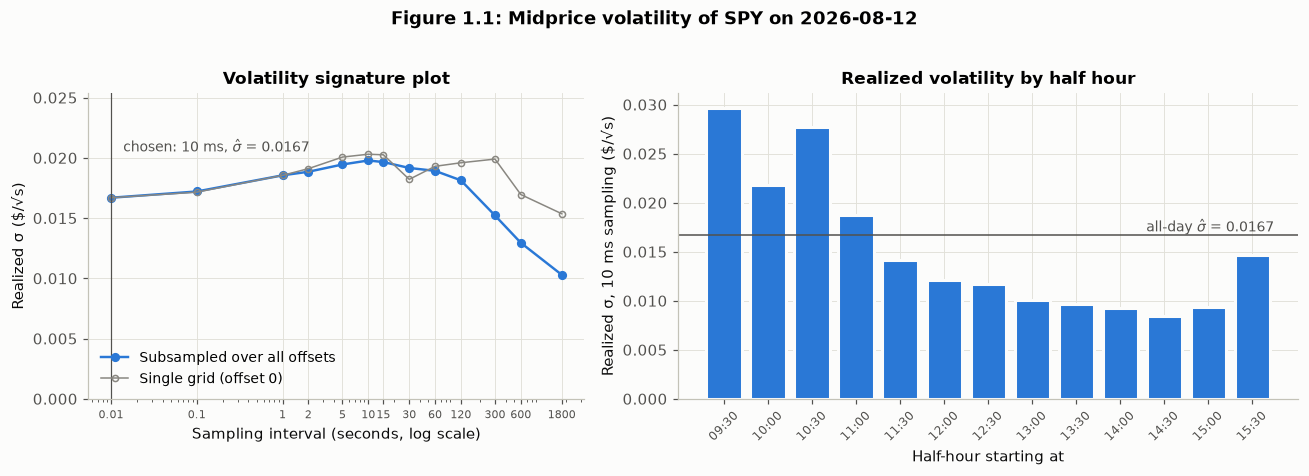

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})

ax1.plot(signature.index, signature["sigma_subsampled"], marker="o", ms=5, color=COLORS["real"],
         label="Subsampled over all offsets")
ax1.plot(signature.index, signature["sigma_single_grid"], marker="o", ms=4, lw=1, color=COLORS["muted"],
         mfc="none", label="Single grid (offset 0)")
ax1.axvline(SIGMA_STEP_S, color=COLORS["ink"], lw=0.8)
ax1.annotate(rf"chosen: 10 ms, $\hat{{\sigma}}$ = {sigma_hat:.4f}", xy=(SIGMA_STEP_S, sigma_hat),
             xytext=(8, 30), textcoords="offset points", fontsize=9, color=COLORS["ink"])
ax1.set_xscale("log")
ax1.set_ylim(0, signature["sigma_single_grid"].max() * 1.25)
ax1.set_xticks(SIGNATURE_INTERVALS, [f"{s:g}" for s in SIGNATURE_INTERVALS], fontsize=7.5)
ax1.set_xlabel("Sampling interval (seconds, log scale)")
ax1.set_ylabel("Realized σ ($/√s)")
ax1.set_title("Volatility signature plot")
ax1.legend(fontsize=9, loc="lower left")

x = np.arange(len(intraday_sigma))
ax2.bar(x, intraday_sigma.to_numpy(), width=0.8, color=COLORS["real"], edgecolor="#fcfcfb", linewidth=2)
ax2.axhline(sigma_hat, color=COLORS["ink"], lw=1)
ax2.text(len(x) - 0.5, sigma_hat, rf"all-day $\hat{{\sigma}}$ = {sigma_hat:.4f}", va="bottom", ha="right",
         fontsize=9, color=COLORS["ink"])
ax2.set_xticks(x, intraday_sigma.index, rotation=45, fontsize=8)
ax2.set_xlabel("Half-hour starting at")
ax2.set_ylabel("Realized σ, 10 ms sampling ($/√s)")
ax2.set_title("Realized volatility by half hour")
fig.suptitle("Figure 1.1: Midprice volatility of SPY on 2026-08-12", fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

**Result:** $\hat{\sigma}$ = 0.0167 dollars per $\sqrt{s}$ at 10 ms sampling. Over the 23,400-second session that is a one-standard-deviation move of \$2.55, or 0.330% of the \$772.70 average mid. Annualized over 252 sessions (regular hours only) it is 5.2%. This was a quiet day for SPY: the mid held a \$3.45 range (\$771.36 to \$774.80) all session. $\sigma$ stays in dollars and seconds for the rest of the notebook.

**Sensitivity to the sampling interval.** The estimate moves with the interval (Figure 1.1, left). It rises from 0.0167 at 10 ms to a peak of 0.0198 at 10 seconds, then falls at longer horizons (0.0152 at 5 minutes and 0.0103 at 30 minutes, although the long end rests on only a handful of observations). The 10 ms figure sits about 12% below the 1-minute estimate of 0.0189. At 10 ms the mid changes in only 3.3% of intervals, and a signature that rises with the interval means short moves tend to continue for a few seconds rather than reverse. The consolidated mid adjusts in small steps as quotes update across venues, so summing tick-level moves captures slightly less variance per second than sampling a few seconds apart. For the simulation the choice matters little. 1c sets $\gamma$ so that $\gamma\hat{\sigma}^2$ matches `main.py`'s skew, which makes the simulated quoting policy almost independent of $\hat{\sigma}$. Its main role is setting how much the simulated mid moves.

**Intraday pattern.** A single daily number hides a lot (Figure 1.1, right). Half-hour volatility runs from 0.030 at the open down to 0.008 in the 14:30 half hour and back to 0.015 into the close, a 3.5x range, with the open heavier than the close. A second spike in the 10:30 half hour contains the largest 5-second move of the day: the mid fell \$1.20 from 10:31:10 to 10:31:15. `simulate_as` assumes a constant $\sigma$, and 1c shows what that assumption costs.

### 1b - Fill-intensity parameters (k, A)

We follow the Module 8 recipe (Hints 1 and 2). Hint 1 walks the tape, tracks the latest bid and ask, and records $\delta$ = |trade price - prevailing mid| for every trade. Hint 2 buckets the $\delta$'s into 14 equal bins up to their 95th percentile, divides each bin's count by elapsed time to get a rate $\hat\lambda(\delta)$, and fits a line to $\log\hat\lambda(\delta)$ against the bin midpoints. Since $\log\lambda(\delta) = \log A - k\delta$, the slope is $-k$ and the intercept is $\log A$. Market-wide trades are a stand-in here: we have no history of fills on our own resting orders, so trade arrivals at each distance are the best available proxy for how often a quote at that distance gets hit.

Three departures from the slide code:
- **Full session, not the first 300,000 messages.** The slide caps the loop at 300k messages to keep the demo fast, but that window runs only from 09:22 to 09:45 and includes eight minutes of pre-market trading. We use every trade from 09:30 to 16:00 so the calibration covers the same session as the backtest. The slide's window is reproduced below for comparison.
- **`parse_event` instead of `fake_broker._parse_line`.** Same parsing logic and the same size fix. Using it here keeps one parser across the whole notebook.
- **Size-0 prints dropped.** These are fractional-share prints (the quantity sits in `frac_size`), so they cannot fill a 1-share order, and `FakeBroker` turns them into 0-share "fills". The fit with them included is reported below.

Distances always use the mid from the last quote before each trade, so nothing from the future enters the estimate.

In [9]:
# Hint 1 from the Module 8 slides, over the whole 09:30-16:00 session (see the changes listed above).
bid = ask = None
deltas, delta_minutes, delta_sizes = [], [], []
with open(TAPE_PATH) as f:
    for line in f:
        msg = parse_event(line)
        if msg.time >= SESSION_CLOSE:
            break
        if isinstance(msg, QuoteUpdate):
            bid, ask = msg.bid, msg.ask
        elif isinstance(msg, TradePrint) and bid is not None and msg.time >= SESSION_OPEN:
            deltas.append(abs(msg.price - (bid + ask) / 2))
            delta_minutes.append(int((msg.time - SESSION_OPEN).total_seconds() // 60))  # for the bootstrap
            delta_sizes.append(msg.size)
delta_sizes = np.array(delta_sizes)
all_deltas = np.array(deltas)
elapsed_seconds = SESSION_SECONDS

# The loop and load_tape() read the tape independently; they must agree trade for trade.
assert np.allclose(all_deltas, np.abs(rth_trades["price"] - rth_trades["mid_before"]).to_numpy())

deltas = all_deltas[delta_sizes > 0]  # drop the fractional-share prints
delta_minutes = np.array(delta_minutes)[delta_sizes > 0]
print(f"{len(all_deltas):,} session trades, {len(deltas):,} with size > 0, over {elapsed_seconds:,.0f} seconds")

465,180 session trades, 398,034 with size > 0, over 23,400 seconds


In [10]:
def module8_fit(deltas, elapsed_seconds, bins=None):
    """Hint 2 from the Module 8 slides: bucket the deltas, turn counts into rates, fit a line to log(rate)."""
    if bins is None:
        bins = np.linspace(0, np.quantile(deltas, 0.95), 15)
    bin_mids = 0.5 * (bins[:-1] + bins[1:])
    counts, _ = np.histogram(deltas, bins=bins)
    rate = counts / elapsed_seconds
    keep = rate > 0  # log is undefined at zero -- drop empty bins
    slope, log_A = np.polyfit(bin_mids[keep], np.log(rate[keep]), 1)
    return -slope, np.exp(log_A), bins, counts


k_hat, A_hat, bins, bin_counts = module8_fit(deltas, elapsed_seconds)
bin_mids = 0.5 * (bins[:-1] + bins[1:])

# For comparison: the fit with the size-0 prints left in, and the slide's own window (first 300k messages, all prints).
k_all, A_all, _, _ = module8_fit(all_deltas, elapsed_seconds)
first_300k = trades[(trades["line"] < 300_000) & trades["mid_before"].notna()]
first_300k_times = pd.concat([quotes.loc[quotes["line"] < 300_000, "time"], trades.loc[trades["line"] < 300_000, "time"]])
slide_elapsed = (first_300k_times.max() - first_300k_times.min()).total_seconds()
k_slide, A_slide, slide_bins, _ = module8_fit(np.abs(first_300k["price"] - first_300k["mid_before"]).to_numpy(),
                                              slide_elapsed)

# Uncertainty: rebuild the session from randomly drawn one-minute blocks and refit (bins held fixed).
in_bins = (deltas >= bins[0]) & (deltas <= bins[-1])
bin_of_delta = np.clip(np.searchsorted(bins, deltas[in_bins], side="right") - 1, 0, len(bin_mids) - 1)
counts_by_minute = np.zeros((SESSION_MINUTES, len(bin_mids)))
np.add.at(counts_by_minute, (delta_minutes[in_bins], bin_of_delta), 1)
assert np.array_equal(counts_by_minute.sum(axis=0), bin_counts)


def fit_bin_rates(rate):
    keep = rate > 0
    slope, log_A = np.polyfit(bin_mids[keep], np.log(rate[keep]), 1)
    return -slope, np.exp(log_A)


rng = np.random.default_rng(SEED)
boot = np.array([fit_bin_rates(counts_by_minute[rng.integers(0, SESSION_MINUTES, SESSION_MINUTES)].sum(axis=0)
                               / SESSION_SECONDS) for _ in range(1000)])
k_ci, A_ci = np.percentile(boot[:, 0], [2.5, 97.5]), np.percentile(boot[:, 1], [2.5, 97.5])

buckets = pd.DataFrame({
    "bin from (c)": 100 * bins[:-1], "bin to (c)": 100 * bins[1:], "trades": bin_counts,
    "rate (trades/s)": bin_counts / elapsed_seconds, "fitted rate": A_hat * np.exp(-k_hat * bin_mids),
})
display(buckets.style.hide(axis="index").format({"bin from (c)": "{:.3f}", "bin to (c)": "{:.3f}", "trades": "{:,}",
                                                 "rate (trades/s)": "{:.4f}", "fitted rate": "{:.4f}"}))
print(f"k_hat = {k_hat:.1f} per $   (95% CI from 1-minute block bootstrap: {k_ci[0]:.1f} - {k_ci[1]:.1f})")
print(f"A_hat = {A_hat:.2f} per s   (95% CI {A_ci[0]:.2f} - {A_ci[1]:.2f}); bins are {100 * (bins[1] - bins[0]):.3f} c wide, "
      f"up to the 95th percentile {100 * bins[-1]:.2f} c")
print(f"  each extra cent from the mid multiplies the rate by exp(-0.01 k) = {np.exp(-0.01 * k_hat):.3f}")
print(f"size-0 prints left in: k = {k_all:.1f}, A = {A_all:.2f}")
print(f"slide's window (first 300,000 messages, {slide_elapsed:,.0f} s incl. pre-market, all prints): "
      f"k = {k_slide:.1f}, A = {A_slide:.2f}; its 95th percentile is {100 * slide_bins[-1]:.1f} c")

# The same fit inside each half hour (bins held fixed), to see how much the parameters drift during the day.
per_half_hour = pd.DataFrame([fit_bin_rates(counts_by_minute[30 * b:30 * (b + 1)].sum(axis=0) / 1800) for b in range(13)],
                             index=half_hour_labels, columns=["k (per $)", "A (per s)"])
per_half_hour["trades/s in the bins"] = [counts_by_minute[30 * b:30 * (b + 1)].sum() / 1800 for b in range(13)]
print("\nModule 8 fit within each half hour:")
print(per_half_hour.round({"k (per $)": 1, "A (per s)": 2, "trades/s in the bins": 1}).T.to_string())

bin from (c),bin to (c),trades,rate (trades/s),fitted rate
0.000,0.393,"111,992",4.7860,2.8906
0.393,0.786,"130,933",5.5954,1.9732
0.786,1.179,"74,347",3.1772,1.3470
1.179,1.571,"30,821",1.3171,0.9196
1.571,1.964,885,0.0378,0.6277
1.964,2.357,"9,909",0.4235,0.4285
2.357,2.750,"7,017",0.2999,0.2925
2.750,3.143,"3,220",0.1376,0.1997
3.143,3.536,"2,943",0.1258,0.1363
3.536,3.929,466,0.0199,0.0931


k_hat = 97.2 per $   (95% CI from 1-minute block bootstrap: 90.4 - 104.7)
A_hat = 3.50 per s   (95% CI 3.17 - 3.88); bins are 0.393 c wide, up to the 95th percentile 5.50 c
  each extra cent from the mid multiplies the rate by exp(-0.01 k) = 0.378
size-0 prints left in: k = 103.7, A = 5.29
slide's window (first 300,000 messages, 1,392 s incl. pre-market, all prints): k = 11.7, A = 2.38; its 95th percentile is 40.0 c

Module 8 fit within each half hour:
                      09:30   10:00  10:30   11:00   11:30   12:00   12:30  13:00  13:30   14:00  14:30   15:00  15:30
k (per $)             87.10  109.60  90.20  110.20  115.50  106.90  124.10  92.00  91.40  106.20  105.8  103.10   91.9
A (per s)              6.38    5.57   3.89    3.42    2.62    2.83    3.05   1.83   1.79    3.15    2.7    2.49    5.7
trades/s in the bins  30.90   20.50  18.10   11.90   10.10   12.70   12.10  10.80  10.60   13.30   13.0   13.50   32.7


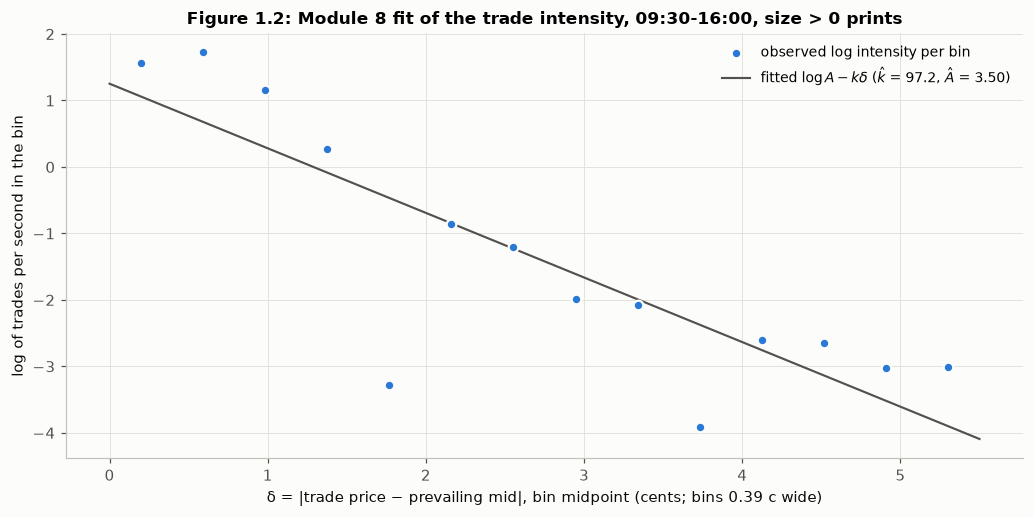

In [11]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
keep = bin_counts > 0
ax.scatter(100 * bin_mids[keep], np.log(bin_counts[keep] / elapsed_seconds), s=40, color=COLORS["real"],
           edgecolor="#fcfcfb", linewidth=1.5, zorder=3, label="observed log intensity per bin")
d_line = np.linspace(0, bins[-1], 100)
ax.plot(100 * d_line, np.log(A_hat) - k_hat * d_line, color=COLORS["ink"], lw=1.4,
        label=rf"fitted $\log A - k\delta$ ($\hat{{k}}$ = {k_hat:.1f}, $\hat{{A}}$ = {A_hat:.2f})")
ax.set_xlabel(f"δ = |trade price − prevailing mid|, bin midpoint (cents; bins {100 * (bins[1] - bins[0]):.2f} c wide)")
ax.set_ylabel("log of trades per second in the bin")
ax.set_title("Figure 1.2: Module 8 fit of the trade intensity, 09:30-16:00, size > 0 prints")
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

**Result:** $\hat{k}$ = 97.2 per dollar and $\hat{A}$ = 3.50 per second, with 95% bootstrap intervals of 90.4-104.7 and 3.17-3.88 (resampling one-minute blocks of the session). Each extra cent from the mid cuts the trade rate by a factor of $e^{-0.972}$ = 0.378. These are the values that go into `simulate_as` in 1c.

Why we trust these values, and where they are fragile:
- *The slide's window gives a very different answer, and it is the wrong one for this purpose.* Running the slide code on its own window (first 300,000 messages, pre-market included) reproduces the slide's k = 11.7 and A = 2.38. Pre-market prints are scattered so widely that the 95th percentile of $\delta$ is 40 cents, the bins come out 2.9 cents wide, and almost every trade lands in the first bin. The fit then can't see the decay that matters for a quote 1-2 cents from the mid. Over the regular session the 95th percentile is 5.5 cents and the bins resolve the touch. Including the size-0 prints moves the estimate much less (k = 103.7, A = 5.29).
- *The bins zig-zag.* Prices sit on a penny grid and the mid on a half-penny grid, so most trades occur at exactly 0, 0.5, 1, 1.5, 2 cents from the mid. With 0.393-cent bins some bins contain one of those values and some don't: the 1.571-1.964 cent bin holds 885 trades against 30,821 and 9,909 in its neighbors (table above). The unweighted line fit weighs all 14 bins equally, so it underpredicts the busy bins at the touch (fitted 2.89 and 1.97 trades/s against 4.79 and 5.60 observed in the first two) and gets pulled around by the sparse bins further out. That is what this recipe does on real tick data, not a coding error.
- *What A means here.* In this recipe A is trades per second in one 0.393-cent bin, both sides of the book combined. It therefore depends on the bin width and is not exactly the per-side hit rate at the touch that `simulate_as` assumes. We validate it against the backtest below and in 1c.
- *The parameters drift during the day.* Fitted half hour by half hour (same bins), A falls from 6.38 per second in the first half hour to 1.79 at 13:30 and recovers to 5.7 in the last, while k ranges from 87 to 124. Trading activity follows the same U shape: 30.9 trades/s in the first half hour, about 10 around midday and 32.7 at the close. That drift is the case for the rolling recalibration in Section 7.

#### Checking the fit against the backtest's own fills

The Module 8 fit treats the whole tape's trades as a proxy for how often an order resting at $\delta$ gets hit. The baseline backtest lets us test that proxy directly, because `TapeBroker` recorded how long the baseline's orders rested at each distance from the mid and how often they filled there. For this check we count trades that reach *at least* $\delta$ on one side of the mid (which is what fills a resting order at $\delta$ in `FakeBroker`), per side and per second. We also merge same-side prints less than 1 ms apart into a single "burst": one marketable order sweeping several venues prints as a run of trades but can usually fill our 1-share quote only once, since the skew moves the quote after the first fill.

In [12]:
DELTA_GRID = np.round(0.005 * np.arange(1, 11), 3)  # 0.5 ... 5 cents from the mid
FIT_RANGE = (0.005, 0.030)
BURST_GAP_S = 0.001
TOL = 1e-9
HALF_CENT = 0.005
calib_trades = rth_trades[rth_trades["size"] > 0]


def aggressor_bursts(trade_frame, gap_s=BURST_GAP_S, merge=True):
    """One row per aggressive burst: consecutive prints on one side of the pre-trade mid, < gap_s apart.

    book_side "bid" = prints below the mid (they would fill a resting buy), "ask" = above it.
    depth = furthest distance from the pre-trade mid reached. merge=False keeps every print as its own row.
    all_dark / any_non_book record whether the burst is made only of off-exchange prints, and whether it
    contains an average-price / derivatively priced / contingent print.
    """
    pieces = []
    for book_side, sign in (("bid", 1.0), ("ask", -1.0)):
        depth = (sign * (trade_frame["mid_before"] - trade_frame["price"])).round(6)
        side = trade_frame.assign(depth=depth, dark=trade_frame["exchange"].eq("DARK"))[depth > TOL]
        gaps = side["time"].diff().dt.total_seconds().fillna(np.inf).to_numpy()
        starts = gaps > gap_s if merge else np.ones(len(side), dtype=bool)
        grouped = side.groupby(np.cumsum(starts)).agg(time=("time", "first"), depth=("depth", "max"),
                                                      prints=("price", "size"), all_dark=("dark", "all"),
                                                      any_non_book=("non_book", "any"))
        pieces.append(grouped.assign(book_side=book_side))
    out = pd.concat(pieces, ignore_index=True)
    out["minute"] = ((out["time"] - SESSION_OPEN).dt.total_seconds() // 60).astype(int)
    return out


def reach_per_side(bursts, deltas=DELTA_GRID):
    """Bursts per side (average of bid and ask) reaching at least each delta over the session."""
    sides = [(bursts.loc[bursts["book_side"] == s, "depth"].to_numpy()[:, None] >= deltas[None, :] - TOL).sum(axis=0)
             for s in ("bid", "ask")]
    return np.mean(sides, axis=0)


def survival_fit(per_side_counts, deltas=DELTA_GRID, fit_range=FIT_RANGE):
    """(k, A) for lambda(delta) = A exp(-k delta) on survival counts: least squares of log rate, weights sqrt(N)."""
    use = (deltas >= fit_range[0] - TOL) & (deltas <= fit_range[1] + TOL)
    n = per_side_counts[use]
    slope, intercept = np.polyfit(deltas[use], np.log(n / SESSION_SECONDS), 1, w=np.sqrt(n))
    return float(-slope), float(np.exp(intercept))


def fill_rate_by_distance(result, deltas=DELTA_GRID):
    """Fills per second of resting time at each quote distance (both sides pooled), and the share of resting time.

    Distances are multiples of half a cent (cent prices against a half-cent mid), so they are grouped as
    integer half-cent ticks to avoid float-equality surprises.
    """
    exposure_ticks = np.rint(result.exposure["distance"] / HALF_CENT).astype(int)
    fill_ticks = np.rint(result.fills["distance"] / HALF_CENT).astype(int)
    seconds = result.exposure.groupby(exposure_ticks.to_numpy())["seconds"].sum()
    n_fills = result.fills.groupby(fill_ticks.to_numpy())["size"].count()
    grid_ticks = np.rint(deltas / HALF_CENT).astype(int)
    rate = (n_fills.reindex(seconds.index, fill_value=0) / seconds).reindex(grid_ticks)
    share = (seconds / seconds.sum()).reindex(grid_ticks, fill_value=0)
    return pd.Series(rate.to_numpy(), index=deltas), pd.Series(share.to_numpy(), index=deltas)


bursts = aggressor_bursts(calib_trades)
burst_counts = reach_per_side(bursts)
print_counts = reach_per_side(aggressor_bursts(calib_trades, merge=False))
lit_counts = reach_per_side(aggressor_bursts(calib_trades[calib_trades["exchange"] != "DARK"]))
book_counts = reach_per_side(aggressor_bursts(calib_trades[~calib_trades["non_book"]]))
bt_rate, bt_share = fill_rate_by_distance(baseline)
fit_share = bt_share.loc[FIT_RANGE[0] - TOL:FIT_RANGE[1] + TOL].sum()

check = pd.DataFrame({
    "prints/s reaching >= delta": print_counts / SESSION_SECONDS,
    "bursts/s reaching >= delta": burst_counts / SESSION_SECONDS,
    "lit-venue bursts/s": lit_counts / SESSION_SECONDS,
    "share of bursts that are all DARK": [bursts.loc[bursts["depth"] >= d - TOL, "all_dark"].mean() for d in DELTA_GRID],
    "backtest fill rate /s": bt_rate.to_numpy(),
    "backtest resting share": bt_share.to_numpy(),
}, index=pd.Index([f"{100 * d:.1f}" for d in DELTA_GRID], name="delta (cents)"))
percent_cols = ["share of bursts that are all DARK", "backtest resting share"]
display(check.style.format({c: "{:.3f}" for c in check.columns} | {c: "{:.1%}" for c in percent_cols}))

survival_fits = pd.DataFrame({
    "bursts, all prints": survival_fit(burst_counts),
    "raw prints": survival_fit(print_counts),
    "bursts, lit venues only": survival_fit(lit_counts),
    "bursts, no average-price / derivatively priced / contingent prints": survival_fit(book_counts),
}, index=["k (per $)", "A (per s, per side)"]).T
display(survival_fits.style.format({"k (per $)": "{:.1f}", "A (per s, per side)": "{:.3f}"}))
k_burst, A_burst = survival_fits.loc["bursts, all prints"]
k_lit, A_lit = survival_fits.loc["bursts, lit venues only"]

in_range = (DELTA_GRID >= FIT_RANGE[0] - TOL) & (DELTA_GRID <= FIT_RANGE[1] + TOL)
print(f"survival fits use 0.5-3c, which holds {fit_share:.1%} of the baseline's resting time; "
      f"bursts per print reaching delta there: {(burst_counts / print_counts)[in_range].min():.2f} - "
      f"{(burst_counts / print_counts)[in_range].max():.2f} ({bursts['prints'].mean():.1f} prints per burst)")
triggered_by_dark = (fills["exchange"] == "DARK").mean()
triggered_by_non_book = fills["conditions"].map(lambda c: bool(NON_BOOK_CONDITIONS.intersection(c))).mean()
print(f"baseline fills triggered by a DARK (off-exchange) print: {triggered_by_dark:.1%}; "
      f"by an average-price / derivatively priced / contingent print: {triggered_by_non_book:.1%}")
deep = bursts[bursts["depth"] >= 0.05 - TOL]
print(f"bursts reaching >= 5c: {len(deep):,}; all-DARK {deep['all_dark'].mean():.0%}, containing an average-price / "
      f"derivatively priced / contingent print {deep['any_non_book'].mean():.0%}")

,prints/s reaching >= delta,bursts/s reaching >= delta,lit-venue bursts/s,share of bursts that are all DARK,backtest fill rate /s,backtest resting share
delta (cents),,,,,,
0.5,6.013,1.975,1.061,46.3%,2.094,6.6%
1.0,3.201,1.113,0.513,50.0%,1.272,8.8%
1.5,1.675,0.576,0.210,55.6%,0.647,23.6%
2.0,1.045,0.376,0.095,66.1%,0.377,29.0%
2.5,0.830,0.312,0.062,72.0%,0.487,15.1%
3.0,0.678,0.268,0.039,77.7%,0.462,9.0%
3.5,0.608,0.245,0.032,79.7%,0.668,3.3%
4.0,0.543,0.225,0.025,81.6%,0.762,1.2%
4.5,0.504,0.210,0.022,82.1%,1.174,0.6%


,k (per $),"A (per s, per side)"
"bursts, all prints",91.5,2.895
raw prints,99.2,9.179
"bursts, lit venues only",146.9,2.181
"bursts, no average-price / derivatively priced / contingent prints",150.2,3.669


survival fits use 0.5-3c, which holds 92.0% of the baseline's resting time; bursts per print reaching delta there: 0.33 - 0.40 (2.9 prints per burst)
baseline fills triggered by a DARK (off-exchange) print: 53.4%; by an average-price / derivatively priced / contingent print: 28.2%
bursts reaching >= 5c: 9,146; all-DARK 83%, containing an average-price / derivatively priced / contingent print 86%


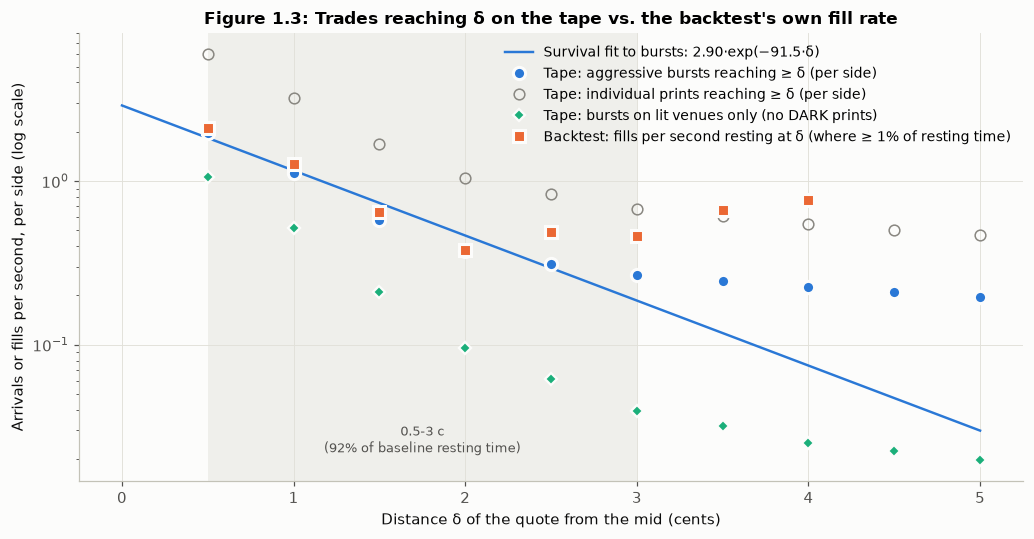

In [13]:
fig, ax = plt.subplots(figsize=(9.5, 5))
lo, hi = FIT_RANGE
ax.axvspan(100 * lo, 100 * hi, color="#e1e0d9", alpha=0.45, lw=0)
ax.text(100 * (lo + hi) / 2, 0.022, f"0.5-3 c\n({fit_share:.0%} of baseline resting time)",
        ha="center", fontsize=8.5, color=COLORS["ink"])
d_fine = np.linspace(0.0, DELTA_GRID.max(), 200)
ax.plot(100 * d_fine, A_burst * np.exp(-k_burst * d_fine), color=COLORS["real"], lw=1.6,
        label=f"Survival fit to bursts: {A_burst:.2f}·exp(−{k_burst:.1f}·δ)")
ax.plot(100 * DELTA_GRID, burst_counts / SESSION_SECONDS, "o", ms=8, color=COLORS["real"], mec="#fcfcfb", mew=2,
        label="Tape: aggressive bursts reaching ≥ δ (per side)")
ax.plot(100 * DELTA_GRID, print_counts / SESSION_SECONDS, "o", ms=7, mfc="none", color=COLORS["muted"],
        label="Tape: individual prints reaching ≥ δ (per side)")
ax.plot(100 * DELTA_GRID, lit_counts / SESSION_SECONDS, "D", ms=6, color=COLORS["accent"], mec="#fcfcfb", mew=1.5,
        label="Tape: bursts on lit venues only (no DARK prints)")
enough_time = bt_share.to_numpy() >= 0.01  # skip distances where the baseline rested < 1% of the time
ax.plot(100 * DELTA_GRID[enough_time], bt_rate.to_numpy()[enough_time], "s", ms=8, color=COLORS["sim"],
        mec="#fcfcfb", mew=2, label="Backtest: fills per second resting at δ (where ≥ 1% of resting time)")
ax.set_yscale("log")
ax.set_xlabel("Distance δ of the quote from the mid (cents)")
ax.set_ylabel("Arrivals or fills per second, per side (log scale)")
ax.set_title("Figure 1.3: Trades reaching δ on the tape vs. the backtest's own fill rate")
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

**What the check shows.** The backtest's fill rate tracks the rate of bursts reaching each distance, not the raw print rate: 2.09 vs 1.98 fills/s at 0.5 cents, 1.27 vs 1.11 at 1 cent, 0.65 vs 0.58 at 1.5 cents and 0.377 vs 0.376 at 2 cents, where the baseline spends most of its resting time. Raw prints overstate it about 3x (2.9 prints per burst). Fitting the same exponential to the burst counts (a survival fit over 0.5-3 cents, which covers 92% of the baseline's resting time) gives k = 91.5, close to the Module 8 value of 97.2, so the two methods agree on how quickly intensity decays with distance. Their A's are not comparable, because they are defined differently (per bin with both sides pooled vs per side at the touch). The practical test of the Module 8 A is whether the simulation in 1c trades about as much as the backtest, and it comes within about 15%.

**A flag for later sections.** 53% of the baseline's fills were triggered by off-exchange (DARK) prints and 28% by prints flagged average-price, derivatively priced or contingent. An order resting on a lit exchange would never be filled by an off-exchange trade, and the flagged prints are not priced off the book in the first place. Most of the fat tail is this kind of flow: 66% of bursts reaching 2 cents consist only of DARK prints, as do 83% of those reaching 5 cents. Restricting to lit-venue bursts gives k = 147 and A = 2.18 per side, and only 0.095 bursts/s reach 2 cents on lit venues, about a quarter of the 0.376 in the full data. The baseline fill model is therefore optimistic before queue position even enters, which we pick up in Section 4. Beyond 3 cents the backtest's points rest on very little time (at most 3.3% at any one distance), so we read nothing into its rising fill rate there.

### 1c - Calibrated `simulate_as` vs. the real `main.py` backtest

**Setup.** We run `simulate_as` over one 23,400-second session (`T = 23_400`) with `dt = 0.01` s, so the simulated Brownian mid steps on the same 10 ms grid used to estimate $\hat{\sigma}$ in 1a. Inputs are $\hat{\sigma}$, $\hat{A}$ and $\hat{k}$ from 1a and 1b, the 09:30 mid as the starting price, and `max_inv = main.MAX_INVENTORY = 20`, the same cap as the backtest. At this step size a quote at the A-S distance has only a 0.5-1.3% chance of being hit in any one step, so the simulator's limit of one fill per side per step costs almost nothing. A check at `dt = 0.005` s follows.

**Risk aversion $\gamma$.** The one parameter the tape can't give us. We set it so the A-S inventory skew $\gamma\sigma^2\tau$ equals `main.py`'s `INVENTORY_SKEW` (1 cent per share) at mid-session, $\tau = T/2$, so both strategies lean on inventory equally hard on average. The A-S skew starts at twice that (2 cents per share at 09:30) and decays to zero at the close, while `main.py`'s stays at 1 cent all day.

**Paths and P&L decomposition.** We run 20 seeds (`SEED + i`). The real backtest is a single path, so we compare it against the spread of simulated paths. Both are marked at the mid and split exactly into **spread capture**, $\sum$(mid at fill - buy price) + $\sum$(sell price - mid at fill), and **inventory P&L**, which is everything else ($\sum$ inventory $\times$ mid change).

**A diagnostic second backtest.** `main.py`'s bid minus its ask always equals (best bid - best ask) - 2 cents, because the inventory skew cancels. When the consolidated NBBO is crossed by 2 cents or more, `main.py`'s bid therefore sits at or above its own ask, and `FakeBroker` fills *both* on any print in between, locking in a loss. To separate that backtest artifact from genuine market behavior, we also run `main.py` with one guard: both quotes are pulled whenever the NBBO the strategy has seen is crossed (`skip_when_crossed` wraps the unchanged handler and uses only messages already read). Same tape, same window. This is a diagnostic for the comparison, not a change to the strategy.

In [14]:
SIM_DT = 0.01  # 10 ms steps: the same grid sigma_hat was estimated on in 1a
CHECK_DT = 0.005
N_SIM_PATHS = 20
gamma = main.INVENTORY_SKEW / (sigma_hat ** 2 * SESSION_SECONDS / 2)
s0 = mid_1s[0]


def as_half_spread(tau):
    return (1 / gamma) * np.log(1 + gamma / k_hat) + 0.5 * gamma * sigma_hat ** 2 * tau


typical_bt_distance = (baseline.exposure["distance"] * baseline.exposure["seconds"]).sum() / baseline.exposure["seconds"].sum()
print(f"gamma = {gamma:.5f} per $; A-S skew per share of inventory: {100 * gamma * sigma_hat ** 2 * SESSION_SECONDS:.2f} c at 09:30, "
      f"{100 * gamma * sigma_hat ** 2 * SESSION_SECONDS / 2:.2f} c at 12:45, 0 at 16:00 (main.py: {100 * main.INVENTORY_SKEW:.2f} c all day)")
print(f"A-S half-spread around its reservation price: {100 * as_half_spread(SESSION_SECONDS):.2f} c at 09:30, "
      f"{100 * as_half_spread(SESSION_SECONDS / 2):.2f} c at 12:45, {100 * as_half_spread(0):.2f} c at 16:00")
print(f"baseline main.py: time-weighted mean quote distance from the mid {100 * typical_bt_distance:.2f} c")
print(f"per-step hit probability at the A-S distance: {1 - np.exp(-A_hat * np.exp(-k_hat * as_half_spread(SESSION_SECONDS)) * SIM_DT):.1%} "
      f"(09:30) to {1 - np.exp(-A_hat * np.exp(-k_hat * as_half_spread(0)) * SIM_DT):.1%} (16:00)")


def run_sim(seed, dt=SIM_DT):
    """One calibrated simulate_as path, reduced to a 1-second grid plus exact fill and capture totals."""
    times, mid, inv, pnl = simulate_as(np.random.default_rng(seed), T=SESSION_SECONDS, dt=dt,
                                       sigma=sigma_hat, gamma=gamma, k=k_hat, A=A_hat, s0=s0,
                                       max_inv=main.MAX_INVENTORY)
    cash = pnl - inv * mid
    d_inv, d_cash = np.diff(inv), np.diff(cash)
    both_sides = (d_inv == 0) & (np.abs(d_cash) > 1e-6)  # a buy and a sell in the same step
    inventory_pnl = np.sum(inv[1:] * np.diff(mid))
    step, per_minute = int(round(1 / dt)), int(round(60 / dt))
    minute_max = np.abs(inv[:SESSION_MINUTES * per_minute]).reshape(SESSION_MINUTES, per_minute).max(axis=1)
    return {"pnl": pnl[::step], "inventory": inv[::step], "minute_max_inv": minute_max,
            "fills": np.abs(d_inv).sum() + 2 * both_sides.sum(), "capture": pnl[-1] - inventory_pnl}


started = walltime.perf_counter()
sims = [run_sim(SEED + i) for i in range(N_SIM_PATHS)]
print(f"\n{N_SIM_PATHS} simulate_as paths in {walltime.perf_counter() - started:.0f} s")
assert all(len(s["pnl"]) == len(paths) for s in sims)

fine = run_sim(SEED, dt=CHECK_DT)
print(f"discretization check (seed {SEED}): {sims[0]['fills']:,.0f} fills at dt = {SIM_DT} s vs "
      f"{fine['fills']:,.0f} at dt = {CHECK_DT} s ({fine['fills'] / sims[0]['fills'] - 1:+.1%})")

gamma = 0.00307 per $; A-S skew per share of inventory: 2.00 c at 09:30, 1.00 c at 12:45, 0 at 16:00 (main.py: 1.00 c all day)
A-S half-spread around its reservation price: 2.03 c at 09:30, 1.53 c at 12:45, 1.03 c at 16:00
baseline main.py: time-weighted mean quote distance from the mid 1.90 c
per-step hit probability at the A-S distance: 0.5% (09:30) to 1.3% (16:00)



20 simulate_as paths in 554 s


discretization check (seed 4170): 47,214 fills at dt = 0.01 s vs 47,234 at dt = 0.005 s (+0.0%)


In [15]:
def skip_when_crossed(tick_handler):
    """Run the tick handler unchanged, then pull both quotes while the NBBO the strategy has seen is crossed."""
    def guarded_handler(broker, book):
        tick_handler(broker, book)
        if book["best_bid"] is not None and book["best_ask"] < book["best_bid"]:
            broker.cancel_order("buy")
            broker.cancel_order("sell")
    return guarded_handler


guarded = run_session(tick_handler=skip_when_crossed(main.handle_next_tick))
guarded_paths = session_paths(guarded.fills, quotes)
assert guarded.messages_read == baseline.messages_read  # same tape, same evaluation window


def double_fills(result):
    """Prints that filled our bid and our ask at once (our own quotes crossed), and the loss they locked in."""
    f = result.fills
    pairs = f[f.groupby("time")["side"].transform("nunique") == 2]
    locked_in = pairs.loc[pairs["side"] == "buy", "price"].sum() - pairs.loc[pairs["side"] == "sell", "price"].sum()
    return pairs["time"].nunique(), locked_in, pairs["time"].drop_duplicates()


n_double, double_loss, double_times = double_fills(baseline)
n_double_guarded, _, _ = double_fills(guarded)
print(f"prints that filled both of main.py's quotes: {n_double} (locked-in loss ${double_loss:.2f}); "
      f"with the guard: {n_double_guarded}")
for label, start in (("09:30 minute", SESSION_OPEN), ("10:31 minute", SESSION_OPEN + pd.Timedelta(minutes=61))):
    in_minute = double_times.between(start, start + pd.Timedelta(minutes=1), inclusive="left").sum()
    print(f"  of which in the {label}: {in_minute}")

# The real backtest's worst drawdown, located on the 1-second grid.
real_pnl = paths["pnl"].to_numpy()
real_dd = np.maximum.accumulate(real_pnl) - real_pnl
trough = int(real_dd.argmax())
peak = int(np.flatnonzero(real_dd[:trough] < 1e-9)[-1])
recovered = trough + int(np.flatnonzero(real_dd[trough:] < 1e-9)[0])
t_peak, t_trough = paths.index[peak], paths.index[trough]
window = fills[fills["time"].between(t_peak, t_trough)]
print(f"\nworst drawdown ${real_dd.max():.2f}: peak {t_peak:%H:%M:%S}, trough {t_trough:%H:%M:%S}, "
      f"recovered {paths.index[recovered]:%H:%M:%S}")
print(f"  mid {mid_1s[peak]:.3f} at the peak, low {mid_1s[peak:trough + 1].min():.3f}, {mid_1s[trough]:.3f} at the trough")
print(f"  fills in the window: {len(window):,}, {(window['bid'] > window['ask']).sum():,} of them against a crossed NBBO; "
      f"prints filling both quotes: {double_times.between(t_peak, t_trough).sum()}")

# Event-level inventory extremes (the 1-second grid can miss them).
event_inventory = fills["signed"].cumsum()
for label, start, end in (("09:30:00-09:31:00", SESSION_OPEN, SESSION_OPEN + pd.Timedelta(minutes=1)),
                          (f"{t_peak:%H:%M:%S}-{t_trough:%H:%M:%S}", t_peak, t_trough)):
    sel = fills["time"].between(start, end)
    print(f"event-level inventory {label}: min {event_inventory[sel].min():+d}, max {event_inventory[sel].max():+d}")

through_mid = fills[fills["distance"] <= 0]
through_capture = (through_mid["signed"] * (through_mid["mid"] - through_mid["price"])).sum()
print(f"\nfills on quotes at or through the mid (skew or a crossed NBBO): {len(through_mid):,} "
      f"({len(through_mid) / len(fills):.1%} of fills), spread capture ${through_capture:.2f}")

prints that filled both of main.py's quotes: 291 (locked-in loss $57.20); with the guard: 0
  of which in the 09:30 minute: 28
  of which in the 10:31 minute: 177

worst drawdown $81.65: peak 10:31:10, trough 10:31:37, recovered 12:36:03
  mid 772.775 at the peak, low 771.355, 772.395 at the trough
  fills in the window: 1,486, 446 of them against a crossed NBBO; prints filling both quotes: 177
event-level inventory 09:30:00-09:31:00: min -20, max +20
event-level inventory 10:31:10-10:31:37: min -20, max +20

fills on quotes at or through the mid (skew or a crossed NBBO): 7,964 (19.4% of fills), spread capture $-235.50


In [16]:
def path_metrics(pnl, inventory, fills, capture):
    pnl, inventory = np.asarray(pnl, dtype=float), np.asarray(inventory, dtype=float)
    drawdown = np.maximum.accumulate(pnl) - pnl  # P&L starts at 0, so the first peak is 0
    return {
        "Fills (shares)": fills,
        "Spread capture ($)": capture,
        "Capture per share (cents)": 100 * capture / fills,
        "Inventory P&L ($)": pnl[-1] - capture,
        "Session P&L at 16:00 ($)": pnl[-1],
        "P&L volatility, 1-min changes ($)": np.std(np.diff(pnl[::60]), ddof=1),
        "Max drawdown ($)": drawdown.max(),
        "Mean |inventory| (shares)": np.abs(inventory).mean(),
        "Max |inventory|, 1-s grid (shares)": np.abs(inventory).max(),
        "Time at |inventory| >= 5 (%)": 100 * np.mean(np.abs(inventory) >= 5),
    }


def real_path_metrics(result, result_paths):
    f = result.fills
    capture = (f["signed"] * (f["mid"] - f["price"])).sum()
    return pd.Series(path_metrics(result_paths["pnl"], result_paths["inventory"], f["size"].sum(), capture))


sim_metrics = pd.DataFrame([path_metrics(s["pnl"], s["inventory"], s["fills"], s["capture"]) for s in sims])
comparison = pd.DataFrame({
    "Real main.py backtest": real_path_metrics(baseline, paths),
    "Real, no quotes while NBBO crossed": real_path_metrics(guarded, guarded_paths),
    "simulate_as median": sim_metrics.median(),
    "sim 10th pct": sim_metrics.quantile(0.10),
    "sim 90th pct": sim_metrics.quantile(0.90),
})
comparison.style.format("{:,.2f}")

,Real main.py backtest,"Real, no quotes while NBBO crossed",simulate_as median,sim 10th pct,sim 90th pct
Fills (shares),"41,072.00","40,178.00","47,177.00","46,759.40","47,504.70"
Spread capture ($),482.26,543.40,486.52,482.31,490.05
Capture per share (cents),1.17,1.35,1.03,1.03,1.03
Inventory P&L ($),-234.71,-232.04,1.38,-4.22,4.32
Session P&L at 16:00 ($),247.54,311.35,486.88,480.72,491.87
"P&L volatility, 1-min changes ($)",3.95,1.09,0.28,0.25,0.30
Max drawdown ($),81.65,20.72,0.88,0.51,1.82
Mean |inventory| (shares),0.51,0.50,0.67,0.66,0.70
"Max |inventory|, 1-s grid (shares)",20.00,20.00,15.00,13.90,20.00
Time at |inventory| >= 5 (%),0.29,0.28,1.19,0.99,1.53


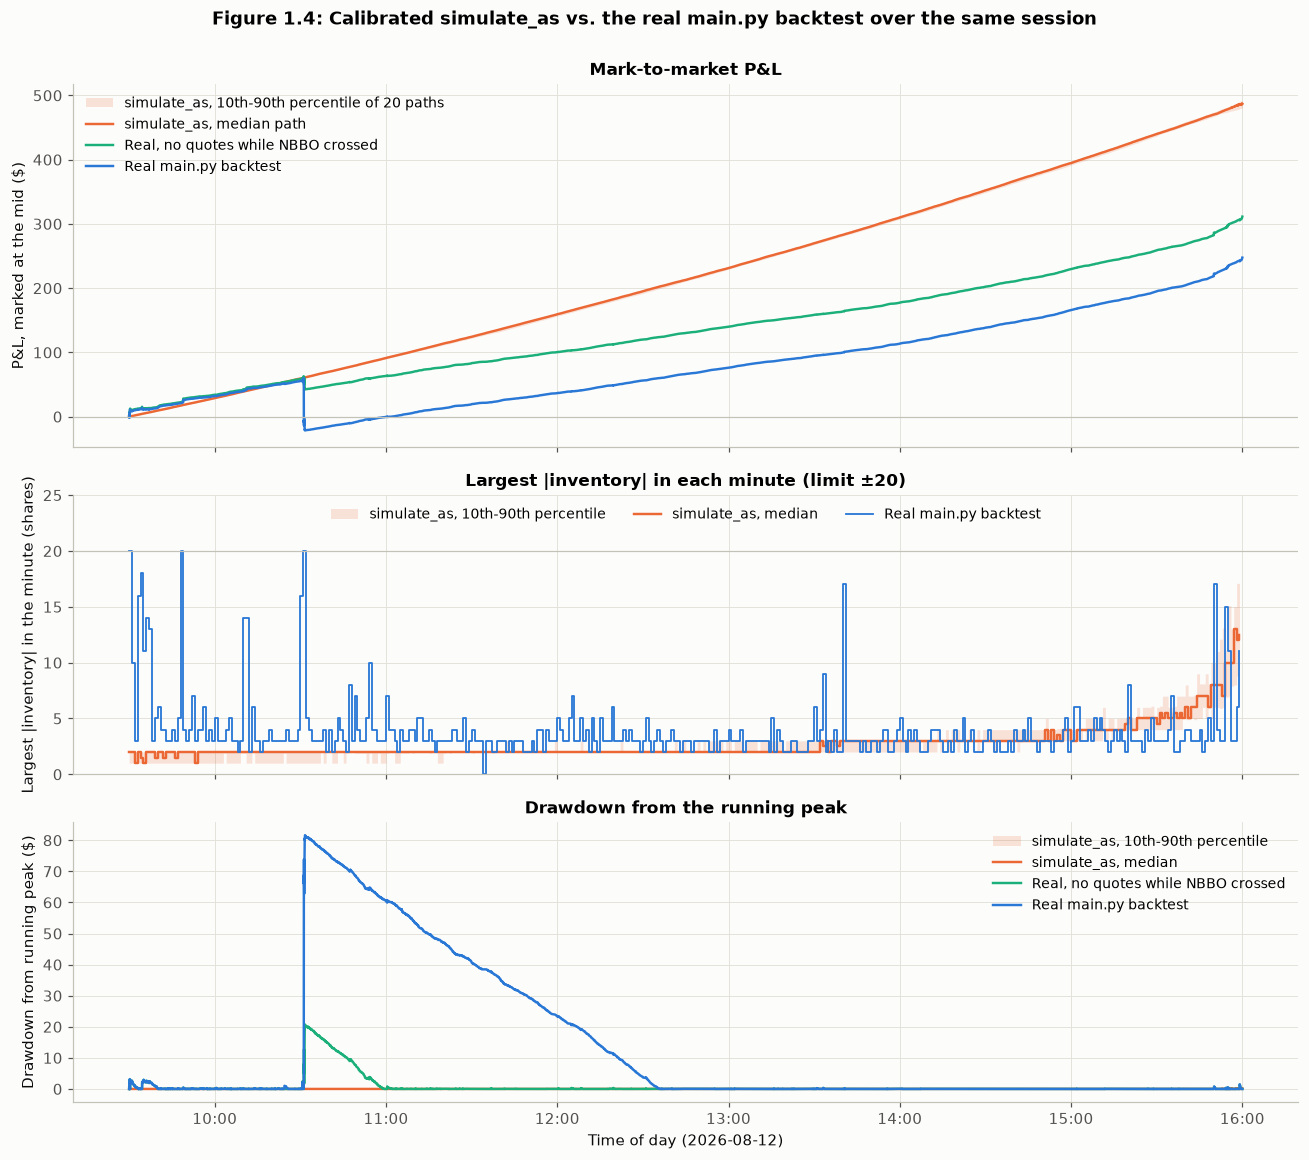

In [17]:
def minute_max_abs_inventory(fills):
    """Largest |inventory| reached in each session minute, at event level (not just on the 1-s grid)."""
    inventory = fills["signed"].cumsum()
    minute = ((fills["time"] - SESSION_OPEN).dt.total_seconds() // 60).astype(int).to_numpy()
    within = inventory.abs().groupby(minute).max().reindex(range(SESSION_MINUTES)).to_numpy()
    at_start = np.abs(np.nan_to_num(prevailing(fills["time"], inventory, session_grid(60)[:-1])))
    return np.fmax(within, at_start)


grid = paths.index
minutes = session_grid(60)[:-1]
sim_pnl = np.vstack([s["pnl"] for s in sims])
sim_dd = np.maximum.accumulate(sim_pnl, axis=1) - sim_pnl
sim_minute_inv = np.vstack([s["minute_max_inv"] for s in sims])
guarded_pnl = guarded_paths["pnl"].to_numpy()
guarded_dd = np.maximum.accumulate(guarded_pnl) - guarded_pnl
LABEL_REAL, LABEL_GUARD = "Real main.py backtest", "Real, no quotes while NBBO crossed"

fig, axes = plt.subplots(3, 1, figsize=(12, 10.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1, 1]})
ax = axes[0]
ax.fill_between(grid, np.percentile(sim_pnl, 10, axis=0), np.percentile(sim_pnl, 90, axis=0),
                color=COLORS["sim"], alpha=0.18, lw=0, label="simulate_as, 10th-90th percentile of 20 paths")
ax.plot(grid, np.median(sim_pnl, axis=0), color=COLORS["sim"], label="simulate_as, median path")
ax.plot(grid, guarded_pnl, color=COLORS["accent"], label=LABEL_GUARD)
ax.plot(grid, real_pnl, color=COLORS["real"], label=LABEL_REAL)
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.set_ylabel("P&L, marked at the mid ($)")
ax.set_title("Mark-to-market P&L")
ax.legend(fontsize=9, loc="upper left")

ax = axes[1]
ax.fill_between(minutes, np.percentile(sim_minute_inv, 10, axis=0), np.percentile(sim_minute_inv, 90, axis=0),
                step="post", color=COLORS["sim"], alpha=0.18, lw=0, label="simulate_as, 10th-90th percentile")
ax.step(minutes, np.median(sim_minute_inv, axis=0), where="post", color=COLORS["sim"], label="simulate_as, median")
ax.step(minutes, minute_max_abs_inventory(fills), where="post", color=COLORS["real"], lw=1.2, label=LABEL_REAL)
ax.axhline(main.MAX_INVENTORY, color="#c3c2b7", lw=0.8)
ax.set_ylim(0, main.MAX_INVENTORY + 5)
ax.set_ylabel("Largest |inventory| in the minute (shares)")
ax.set_title(f"Largest |inventory| in each minute (limit ±{main.MAX_INVENTORY})")
ax.legend(fontsize=9, loc="upper center", ncols=3)

ax = axes[2]
ax.fill_between(grid, np.percentile(sim_dd, 10, axis=0), np.percentile(sim_dd, 90, axis=0),
                color=COLORS["sim"], alpha=0.18, lw=0, label="simulate_as, 10th-90th percentile")
ax.plot(grid, np.median(sim_dd, axis=0), color=COLORS["sim"], label="simulate_as, median")
ax.plot(grid, guarded_dd, color=COLORS["accent"], label=LABEL_GUARD)
ax.plot(grid, real_dd, color=COLORS["real"], label=LABEL_REAL)
ax.set_ylabel("Drawdown from running peak ($)")
ax.set_title("Drawdown from the running peak")
ax.legend(fontsize=9, loc="upper right")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel("Time of day (2026-08-12)")
fig.suptitle("Figure 1.4: Calibrated simulate_as vs. the real main.py backtest over the same session",
             fontweight="bold", y=1.0)
fig.tight_layout()
plt.show()

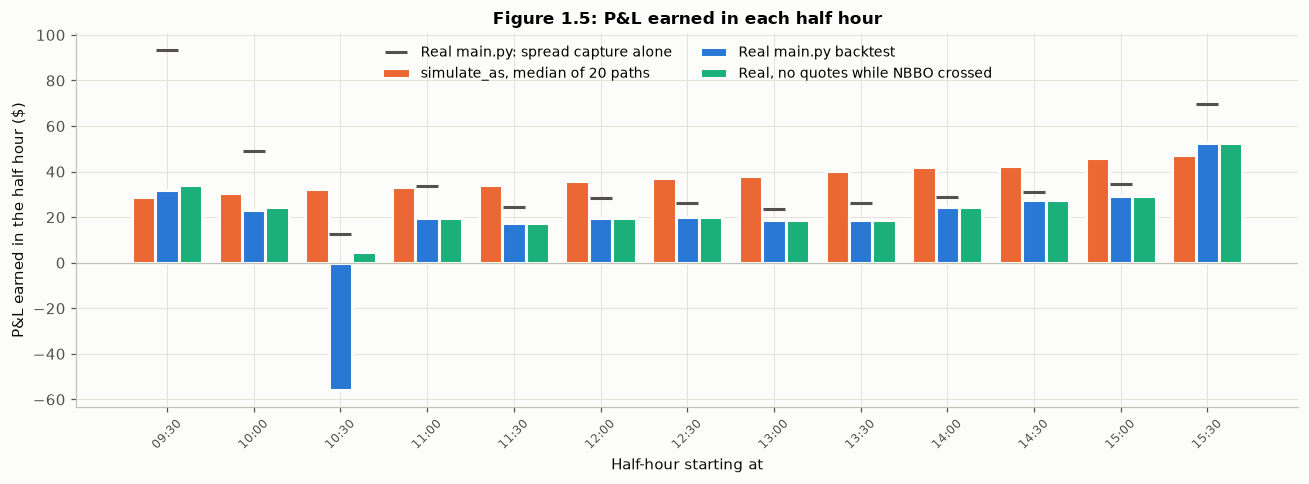

                       09:30  10:00  10:30  11:00  11:30  12:00  12:30  13:00  13:30  14:00  14:30  15:00  15:30
sim median P&L          28.9   30.5   32.2   33.2   34.1   35.7   37.0   38.3   40.1   41.9   42.6   45.9   47.1
real P&L                32.1   23.4  -55.8   19.7   17.3   19.6   19.9   18.5   19.0   24.7   27.5   29.2   52.4
real spread capture     93.3   49.0   12.7   33.9   24.6   28.3   26.3   23.6   26.3   28.9   31.1   34.5   69.6
real inventory P&L     -61.2  -25.7  -68.6  -14.2   -7.3   -8.7   -6.4   -5.1   -7.3   -4.2   -3.6   -5.3  -17.2
guarded P&L             34.1   24.4    4.9   19.7   17.3   19.6   19.9   18.5   19.0   24.7   27.5   29.2   52.4
guarded inventory P&L  -61.0  -25.5  -66.3  -14.2   -7.3   -8.7   -6.4   -5.1   -7.3   -4.2   -3.6   -5.3  -17.2

real inventory P&L negative in 13 of 13 half hours (guarded run: 13 of 13)


In [18]:
def half_hour_increments(pnl_1s):
    return np.diff(np.asarray(pnl_1s)[::1800])


def half_hour_capture(result):
    f = result.fills
    bucket = ((f["time"] - SESSION_OPEN).dt.total_seconds() // 1800).astype(int)
    return (f["signed"] * (f["mid"] - f["price"])).groupby(bucket).sum().reindex(range(13), fill_value=0).to_numpy()


real_inc, guarded_inc = half_hour_increments(real_pnl), half_hour_increments(guarded_pnl)
sim_inc_median = np.median(np.vstack([half_hour_increments(s["pnl"]) for s in sims]), axis=0)
real_capture_hh = half_hour_capture(baseline)

x = np.arange(13)
width = 0.27
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x - width, sim_inc_median, width=width, color=COLORS["sim"], edgecolor="#fcfcfb", linewidth=2,
       label="simulate_as, median of 20 paths")
ax.bar(x, real_inc, width=width, color=COLORS["real"], edgecolor="#fcfcfb", linewidth=2, label=LABEL_REAL)
ax.bar(x + width, guarded_inc, width=width, color=COLORS["accent"], edgecolor="#fcfcfb", linewidth=2, label=LABEL_GUARD)
ax.plot(x, real_capture_hh, "_", ms=14, mew=2, color=COLORS["ink"], label="Real main.py: spread capture alone")
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.set_xticks(x, half_hour_labels, rotation=45, fontsize=8)
ax.set_xlabel("Half-hour starting at")
ax.set_ylabel("P&L earned in the half hour ($)")
ax.set_title("Figure 1.5: P&L earned in each half hour")
ax.legend(fontsize=9, loc="upper center", ncols=2)
fig.tight_layout()
plt.show()

half_hours_table = pd.DataFrame({
    "sim median P&L": sim_inc_median, "real P&L": real_inc, "real spread capture": real_capture_hh,
    "real inventory P&L": real_inc - real_capture_hh, "guarded P&L": guarded_inc,
    "guarded inventory P&L": guarded_inc - half_hour_capture(guarded),
}, index=half_hour_labels)
print(half_hours_table.round(1).T.to_string())
print(f"\nreal inventory P&L negative in {(half_hours_table['real inventory P&L'] < 0).sum()} of 13 half hours "
      f"(guarded run: {(half_hours_table['guarded inventory P&L'] < 0).sum()} of 13)")

**Where they agree.** Calibrated to this tape, the simulation gets volume and spread capture about right. It fills 47,177 shares (median of 20 paths, 10th-90th percentile 46,759 to 47,505) against 41,072 in the backtest, about 15% more, and its spread capture is \$487 vs \$482. Some of that agreement is offsetting errors. The simulation trades more but earns less per share (1.03 cents vs 1.17), partly because A-S quotes tighter (1.53 cents from the mid at mid-session vs 1.90 cents on average for `main.py`). On the backtest side, 19.4% of fills come from quotes that the skew or a crossed NBBO pushed to or through the mid, and those fills earn negative spread (-\$235.50 in total). Typical inventory also looks similar: both books spend almost the entire session within a few shares of flat (mean |inventory| 0.51 real vs 0.67 simulated).

**Where they diverge.** Everything that depends on what the price does *after* the fill.
- *Inventory P&L.* In the simulation it is noise around zero (between -\$4.22 and +\$4.32 in 80% of paths). The real book loses \$234.71 on inventory, roughly half its spread capture, and loses on inventory in all 13 half hours (table above). It finishes at \$247.54, 51% of the simulated median of \$486.88.
- *Risk.* Simulated P&L is close to a straight line, with 1-minute P&L volatility of \$0.28 and a max drawdown of \$0.88. The real book's are \$3.95 and \$81.65.
- *Inventory spikes.* Real inventory hits the $\pm$20 limit in fast markets: at event level it swings from -20 to +20 both in the first minute after the open and during 10:31:10-10:31:37. Simulated inventory is loosest near the close, because the A-S skew decays to zero there. It spends 1.19% of the session at |inventory| $\geq$ 5 vs 0.29% for the real book.

**Why they diverge.**

1. *Most of the drawdown is a backtest artifact.* `main.py`'s bid and ask are always 2 cents wider than the NBBO, so when the NBBO is crossed by 2 cents or more (4.8 seconds of the session) its bid sits at or above its own ask and `FakeBroker` fills both on the same print. That happened on 291 prints and locked in \$57.20 of losses, 177 of them in the 10:31 minute alone. Over the worst drawdown (10:31:10 to 10:31:37) the backtest filled 1,486 shares, 446 of them against a crossed NBBO, while the mid fell from 772.775 to 771.355 and recovered to 772.395. With the crossed-market guard the same strategy ends at \$311.35 instead of \$247.54, the max drawdown shrinks from \$81.65 to \$20.72, and 1-minute P&L volatility from \$3.95 to \$1.09. Most of the 10:31 loss comes from the `main.py` + `FakeBroker` combination, not market risk; a production quoting engine would never cross its own quotes. We carry this into Sections 4 and 7.
2. *Adverse selection explains the P&L gap.* The guard barely moves inventory P&L (-\$232.04, still negative in all 13 half hours). In A-S, fills arrive as a Poisson process independent of the Brownian mid, so inventory picked up says nothing about the next price move and inventory P&L averages zero. On the real tape, the burst that hits our bid is the same selling that pushes the mid down: we get filled *because* the price is moving through our quote. The cost is about 0.57 cents per share filled, against 1.17 cents captured (1.35 with the guard). This is the adverse-selection term in Module 8's edge equation, which Section 6 measures directly with markout.
3. *Non-stationarity and jumps explain the rest of the risk gap.* Even without the artifact, the real drawdown is about 24x the simulated median and 1-minute P&L volatility about 4x. The model uses one $\sigma$ and one $\lambda$ all day, but on the tape volatility swings about 3.5x (Figure 1.1) and trading activity is roughly three times higher in the first and last half hours than at midday (30.9 and 32.7 trades/s vs about 10, from the half-hour fits in 1b). At 10:31 the mid also moved 32 of the model's 5-second standard deviations in 5 seconds. Risk arrives in episodes, and the inventory spikes happen inside them.
4. *The policies also differ*, and we have not isolated that effect. A-S skews 2 cents per share at the open (twice `main.py`'s 1 cent) and nothing at the close, and it quotes off a continuous mid rather than one tick behind the touch on a penny grid.

**Bottom line.** Calibrated to this tape, `simulate_as` is a reasonable guide to how often we trade and what we earn from the spread. What it misses is what happens after each fill: the real book gives back about half its spread capture to adverse selection. Used as a forecast for `main.py` as written, it would overstate the day's frictionless P&L by about 97% (nearly double) and understate the max drawdown by about 93x. Even with the self-crossing artifact removed it overstates P&L by about 56% and understates drawdown by about 24x.

### Section 1 summary: calibrated parameters carried forward

| Parameter | Estimate | Uncertainty | Units | From |
|---|---|---|---|---|
| $\sigma$ (mid volatility) | 0.0167 | 0.0167 to 0.0198 across 10 ms to 2 min sampling (0.0189 at 1 min) | dollars per $\sqrt{s}$ | 1a, 10 ms realized volatility |
| $k$ (Module 8 fit) | 97.2 | 90.4 to 104.7 bootstrap; 103.7 with size-0 prints; 87 to 124 across half hours | per dollar | 1b, Hints 1 and 2, full session, size > 0 prints |
| $A$ (Module 8 fit) | 3.50 | 3.17 to 3.88 bootstrap; 5.29 with size-0 prints; 1.8 to 6.4 across half hours | trades per second in a 0.393 cent bin, both sides | 1b |
| $k$, $A$ from the survival fit to bursts | 91.5, 2.90 | check only | per dollar, per second per side | 1b check against the backtest |
| $k$, $A$ using lit venues only | 147, 2.18 | check only | same as above | 1b check, probably the better guide for a real lit quote (Section 4) |
| $\gamma$ (risk aversion) | 0.00307 | chosen, not estimated: $\gamma\hat{\sigma}^2 T/2$ = `INVENTORY_SKEW` | per dollar | 1c |

The Module 8 $(k, A)$ drive the simulation, and the burst fits serve as a check against the backtest's own fills. All are full-session, in-sample estimates, and the half-hour fits in 1b show they drift intraday. For Section 7's rolling recalibration, `module8_fit` and `realized_sigma` (on the 10 ms grid) can be rerun on only the data available at each refit time.

**Carried into Sections 2-7.** Two features of the baseline backtest inflate its results independently of queue position: 53% of its fills are triggered by off-exchange prints (1b), and its own quotes cross when the NBBO is crossed by 2 cents or more (1c).

## Section 2 - Trading Fees and Rebates: How Much Do They Matter?

**What stays fixed.** Strategy (`main.handle_next_tick`), fill model (`FakeBroker` matching), zero latency and the full-session window are unchanged from the Section 1 baseline. Only the fee schedule varies. Every P&L figure in this section is therefore after fees and rebates but before any latency, queue-position or adverse-selection haircut (Sections 3-6). None of it is an estimate of live P&L.

**Bookkeeping** (as in Setup). *Gross P&L* is session P&L before fees and rebates: cash plus 16:00 inventory marked at the mid, \$247.54 from Section 1. Maker rebates add, taker fees subtract, and *net P&L* = gross P&L + rebates - fees - flattening cost.

**Fee levels** come from Module 8's maker-taker slide: a maker rebate of roughly \$0.0020-0.0028 per share (headline $\rho$ = \$0.0025, the middle of the range) and a taker fee of roughly \$0.0030 per share. An inverted venue reverses the signs, charging the maker and paying the taker, which appears here as a negative $\rho$.

### 2a - Maker rebate on every fill

`FeeBroker` extends `TapeBroker` from Section 1. After the inherited `poll()` returns, it adds $\rho \times$ size to `rebate_total` for every `OrderFilled`, buy or sell. The 8,874 zero-share "fills" from fractional prints earn nothing because their size is 0. Matching is untouched, and `book["cash"]` in `main.py` remains pure trading cash, so rebates are tracked separately rather than mixed into gross P&L.

We validate `FeeBroker` on the first 300,000 messages at the headline $\rho$ = \$0.0025 and at an inverted $\rho$ = -\$0.0030. Both runs must reproduce the plain `TapeBroker`'s fills exactly and book $\rho$ on every filled share, which is what "holding everything else fixed" means here. Because the rebate never changes a fill, full-day rebate revenue is simply $\rho \times$ the baseline's 41,072 filled shares, with no need to replay the day.

In [19]:
from functools import partial

RHO_HEADLINE = 0.0025                 # $/share, middle of Module 8's 0.0020-0.0028 maker rebate
RHO_REALISTIC = (0.0020, 0.0028)
RHO_INVERTED_CHECK = -0.0030          # an inverted venue charging the maker
TAKER_FEE = 0.0030                    # $/share, Module 8's taker fee


class FeeBroker(TapeBroker):
    """TapeBroker that books a maker rebate of `maker_rebate` dollars per share on every OrderFilled."""

    def __init__(self, data_path, maker_rebate=0.0):
        super().__init__(data_path)
        self.maker_rebate = maker_rebate
        self.rebate_total = 0.0
        self.rebated_shares = 0

    def poll(self):
        messages = super().poll()
        for message in messages:
            if isinstance(message, OrderFilled):
                self.rebate_total += self.maker_rebate * message.size
                self.rebated_shares += message.size
        return messages


CHECK_WINDOW = 300_000  # first 300k messages: enough for a fill-for-fill check without replaying the whole day
fill_key = ["time", "side", "price", "size"]
plain = run_session(max_messages=CHECK_WINDOW)
check_shares = int(plain.fills["size"].sum())
for rho in (RHO_HEADLINE, RHO_INVERTED_CHECK):
    run = run_session(broker_cls=partial(FeeBroker, maker_rebate=rho), max_messages=CHECK_WINDOW)
    assert run.fills[fill_key].equals(plain.fills[fill_key])        # the rebate changes no fill
    assert run.broker.rebated_shares == check_shares                 # every filled share earned rho
    assert np.isclose(run.broker.rebate_total, rho * check_shares)
    print(f"rho = ${rho:+.4f}/share: {len(run.fills):,} fills identical to TapeBroker on the first {CHECK_WINDOW:,} "
          f"messages; rebates booked ${run.broker.rebate_total:,.2f} = rho x {check_shares:,} shares")
del plain, run

gross_pnl = paths["pnl"].iloc[-1]          # Section 1 baseline, 16:00 inventory marked at the mid
filled_shares = int(fills["size"].sum())

rho = $+0.0025/share: 4,292 fills identical to TapeBroker on the first 300,000 messages; rebates booked $10.73 = rho x 4,292 shares


rho = $-0.0030/share: 4,292 fills identical to TapeBroker on the first 300,000 messages; rebates booked $-12.88 = rho x 4,292 shares


In [20]:
headline_rebates = RHO_HEADLINE * filled_shares  # exact, by the check above
real_capture = (fills["signed"] * (fills["mid"] - fills["price"])).sum()  # spread capture vs the pre-trade mid (1c)
attribution = pd.DataFrame({
    "maker rebate rho ($/share)": [RHO_REALISTIC[0], RHO_HEADLINE, RHO_REALISTIC[1]],
}).set_index("maker rebate rho ($/share)")
attribution["rebate revenue ($)"] = attribution.index * filled_shares
attribution["as % of gross P&L"] = 100 * attribution["rebate revenue ($)"] / gross_pnl
attribution["net P&L before flattening ($)"] = gross_pnl + attribution["rebate revenue ($)"]
attribution["rebate share of net P&L (%)"] = 100 * attribution["rebate revenue ($)"] / attribution["net P&L before flattening ($)"]

print(f"gross P&L ${gross_pnl:,.2f} on {filled_shares:,} filled shares = {100 * gross_pnl / filled_shares:.3f} c per share "
      f"(spread capture {100 * real_capture / filled_shares:.3f} c, inventory P&L {100 * (gross_pnl - real_capture) / filled_shares:+.3f} c)")
print(f"headline rebate revenue (rho = ${RHO_HEADLINE}): ${headline_rebates:,.2f} = {headline_rebates / gross_pnl:.1%} of gross P&L")
display(attribution.style.format({"rebate revenue ($)": "{:,.2f}", "as % of gross P&L": "{:.1f}",
                                  "net P&L before flattening ($)": "{:,.2f}", "rebate share of net P&L (%)": "{:.1f}"}))

# Caveat on "always the passive side": main.py re-sends both quotes after every message, so the order behind each
# fill was placed against the NBBO logged with that fill. Buys priced at/above the offer, or sells at/below the bid,
# were marketable when placed and would really have executed as taker orders.
marketable = (((fills["side"] == "buy") & (fills["price"] >= fills["ask"] - 1e-9))
              | ((fills["side"] == "sell") & (fills["price"] <= fills["bid"] + 1e-9)))
marketable_shares = int(fills.loc[marketable, "size"].sum())
print(f"\nfills on quotes that were marketable when placed: {marketable_shares:,} shares "
      f"({marketable_shares / filled_shares:.1%}; {int((marketable & (fills['bid'] > fills['ask'])).sum()):,} of them in a crossed NBBO)")
print(f"if those paid the taker fee instead of earning the headline rebate: "
      f"-${marketable_shares * (RHO_HEADLINE + TAKER_FEE):,.2f} (fees only; price improvement not modelled)")

gross P&L $247.54 on 41,072 filled shares = 0.603 c per share (spread capture 1.174 c, inventory P&L -0.571 c)
headline rebate revenue (rho = $0.0025): $102.68 = 41.5% of gross P&L


,rebate revenue ($),as % of gross P&L,net P&L before flattening ($),rebate share of net P&L (%)
maker rebate rho ($/share),,,,
0.002000,82.14,33.2,329.68,24.9
0.002500,102.68,41.5,350.22,29.3
0.002800,115.00,46.5,362.54,31.7



fills on quotes that were marketable when placed: 5,728 shares (13.9%; 756 of them in a crossed NBBO)
if those paid the taker fee instead of earning the headline rebate: -$31.50 (fees only; price improvement not modelled)


**Result:** at the headline $\rho$ = \$0.0025 the strategy earns **\$102.68 in rebates** on 41,072 filled shares. That is **41.5% of its \$247.54 gross P&L**, and 33.2-46.5% across Module 8's \$0.0020-0.0028 range. Rebates loom this large because they are paid per share while the gross edge per share is thin: 0.603 cents (1.174 cents of spread capture less 0.571 cents lost on inventory), against a 0.250-cent rebate. Net P&L before flattening is \$350.22, 29% of it rebate.

*Caveat on "always the passive side".* The prompt treats every fill as passive, and so does our headline figure. But `main.py` re-sends both quotes after every message, and the inventory skew sometimes places a quote at or through the far side of the NBBO. 5,728 filled shares (13.9%) came from quotes that were already marketable when placed, 756 of them while the NBBO was crossed. On a real exchange those would have executed immediately as taker orders. Charging them the 0.30-cent taker fee instead of paying the 0.25-cent rebate costs \$31.50. That counts fees only; a marketable order would also have executed at the better far-side price, which partly offsets it.

### 2b - Rebate sweep and breakeven

Because fills don't depend on $\rho$ (verified above), net P&L is exactly linear in it: net($\rho$) = gross + $\rho \times$ filled shares. We evaluate it from -\$0.0090 to +\$0.0030 per share in \$0.0005 steps, plus the realistic endpoints. That covers zero, Module 8's realistic rebates, and inverted venues far enough out to bracket the breakeven.

The **breakeven rebate** solves net($\rho^*$) = 0, so $\rho^*$ = -gross / filled shares. We report it with and without the end-of-day flattening cost from 2c. We also report it for the 1c diagnostic variant that stops quoting while the NBBO is crossed, since the breakeven depends directly on how much gross P&L the backtest credits the strategy with.

In [21]:
NBBO_AT_CLOSE = {side: float(prevailing(quotes["time"], quotes[side], [SESSION_CLOSE])[0]) for side in ("bid", "ask")}


def flatten_at_close(result_paths, taker_fee=TAKER_FEE):
    """One marketable order at 16:00 that closes the inventory against the prevailing NBBO, costed against the mid mark."""
    q = float(result_paths["inventory"].iloc[-1])
    bid, ask = NBBO_AT_CLOSE["bid"], NBBO_AT_CLOSE["ask"]
    mid = 0.5 * (bid + ask)
    exit_price = bid if q > 0 else ask
    return {"inventory (shares)": q, "exit price": exit_price,
            "spread cost vs mid ($)": abs(q) * abs(mid - exit_price),
            "taker fee ($)": taker_fee * abs(q),
            "total flattening cost ($)": abs(q) * abs(mid - exit_price) + taker_fee * abs(q)}


variants_2 = {
    "main.py baseline": (gross_pnl, filled_shares, flatten_at_close(paths)),
    "baseline, no quotes while NBBO crossed": (guarded_paths["pnl"].iloc[-1], int(guarded.fills["size"].sum()),
                                               flatten_at_close(guarded_paths)),
}


def net_pnl(gross, shares, rho, flatten_cost=0.0):
    return gross + rho * shares - flatten_cost



RHO_GRID = np.unique(np.round(np.r_[np.arange(-0.0090, 0.00301, 0.0005), RHO_REALISTIC, RHO_HEADLINE], 4))
sweep = pd.DataFrame({"rho ($/share)": RHO_GRID})
breakevens = {}
for name, (gross, shares, flat) in variants_2.items():
    sweep[f"{name}: net, held at mid ($)"] = net_pnl(gross, shares, RHO_GRID)
    sweep[f"{name}: net, flattened ($)"] = net_pnl(gross, shares, RHO_GRID, flat["total flattening cost ($)"])
    breakevens[name] = {"held to the close, marked at the mid": -gross / shares,
                        "flattened at 16:00 with taker fee": -(gross - flat["total flattening cost ($)"]) / shares}
    assert RHO_GRID.min() < min(breakevens[name].values()) < RHO_GRID.max()  # the grid brackets the breakeven

shown = [-0.009, -0.008, -0.007, -0.006, -0.005, -0.004, -0.003, -0.002, -0.001, 0.0, 0.001, 0.002, 0.0025, 0.0028, 0.003]
shown_rows = np.isclose(sweep["rho ($/share)"].to_numpy()[:, None], shown).any(axis=1)
display(sweep[shown_rows].style.hide(axis="index")
        .format({"rho ($/share)": "{:+.4f}"} | {c: "{:,.2f}" for c in sweep.columns[1:]}))
breakeven_table = pd.DataFrame(breakevens).T
print("Breakeven maker rebate rho* ($/share; negative = the maker pays):")
print(breakeven_table.map(lambda v: f"{v:+.5f}  ({100 * v:+.3f} c)").to_string())

rho ($/share),"main.py baseline: net, held at mid ($)","main.py baseline: net, flattened ($)","baseline, no quotes while NBBO crossed: net, held at mid ($)","baseline, no quotes while NBBO crossed: net, flattened ($)"
-0.0090,-122.11,-122.25,-50.25,-50.39
-0.0080,-81.04,-81.17,-10.07,-10.21
-0.0070,-39.96,-40.10,30.10,29.97
-0.0060,1.11,0.97,70.28,70.14
-0.0050,42.18,42.04,110.46,110.32
-0.0040,83.25,83.11,150.64,150.50
-0.0030,124.32,124.19,190.82,190.68
-0.0020,165.40,165.26,230.99,230.86
-0.0010,206.47,206.33,271.17,271.03
+0.0000,247.54,247.40,311.35,311.21


Breakeven maker rebate rho* ($/share; negative = the maker pays):
                                       held to the close, marked at the mid flattened at 16:00 with taker fee
main.py baseline                                       -0.00603  (-0.603 c)              -0.00602  (-0.602 c)
baseline, no quotes while NBBO crossed                 -0.00775  (-0.775 c)              -0.00775  (-0.775 c)


**Result:** net P&L rises linearly in $\rho$, and every 0.1 cents of rebate is worth \$41.07 over the session (41,072 shares). It crosses zero at **$\rho^*$ = -\$0.00602 per share (-0.602 cents)** after end-of-day flattening, or -0.603 cents without it. This frictionless baseline stays profitable until a venue *charges* makers about 0.60 cents a share, twice Module 8's 0.30-cent taker fee. At an inverted -0.30 cents it still makes \$124.19 after flattening. The breakeven is only as reliable as the gross P&L behind it: without the self-crossing artifact (the guarded run from 1c, gross \$311.35 on 40,178 shares) it moves out to -0.775 cents.

### 2c - End-of-day flattening with a taker fee

At 16:00 `main.py` cancels its quotes and simply holds whatever inventory is left. Here we force the book flat instead. One marketable order at 16:00 sells a long position at the best bid (or buys back a short at the best ask), using the NBBO already seen at that point. It pays the \$0.0030-per-share taker fee, and **it is the only trade that does**. Every other fill keeps its maker rebate. Relative to the mid mark used for gross P&L, it costs half the spread per share plus the fee. A few shares at the top of SPY's book raise no depth concerns.

In [22]:
flattening = pd.DataFrame({name: flat for name, (_, _, flat) in variants_2.items()})
print(f"NBBO at 16:00:00: bid {NBBO_AT_CLOSE['bid']:.2f} / ask {NBBO_AT_CLOSE['ask']:.2f} "
      f"(spread {100 * (NBBO_AT_CLOSE['ask'] - NBBO_AT_CLOSE['bid']):.0f} c)")
display(flattening.style.format("{:,.3f}"))

flat = variants_2["main.py baseline"][2]
fee_share_of_rebates = flat["taker fee ($)"] / headline_rebates
print(f"taker fee on the flattening trade: ${flat['taker fee ($)']:.3f} = {fee_share_of_rebates:.4%} of the day's "
      f"${headline_rebates:,.2f} headline rebate revenue (the rebate on {flat['taker fee ($)'] / RHO_HEADLINE:.1f} filled shares)")
print(f"whole flattening cost (spread + fee): ${flat['total flattening cost ($)']:.3f} = "
      f"{flat['total flattening cost ($)'] / headline_rebates:.3%} of the rebate revenue")
worst_inventory = main.MAX_INVENTORY
print(f"worst case, flattening the full {worst_inventory}-share limit at this spread: fee ${TAKER_FEE * worst_inventory:.3f}, "
      f"spread ${worst_inventory * (NBBO_AT_CLOSE['ask'] - NBBO_AT_CLOSE['bid']) / 2:.2f}")

NBBO at 16:00:00: bid 772.59 / ask 772.63 (spread 4 c)


,main.py baseline,"baseline, no quotes while NBBO crossed"
inventory (shares),6.000,6.000
exit price,772.590,772.590
spread cost vs mid ($),0.120,0.120
taker fee ($),0.018,0.018
total flattening cost ($),0.138,0.138


taker fee on the flattening trade: $0.018 = 0.0175% of the day's $102.68 headline rebate revenue (the rebate on 7.2 filled shares)
whole flattening cost (spread + fee): $0.138 = 0.134% of the rebate revenue
worst case, flattening the full 20-share limit at this spread: fee $0.060, spread $0.40


**Result:** the book ends the session long 6 shares against a 16:00 NBBO of 772.59 / 772.63, a relatively wide 4 cents. Selling at the bid costs \$0.120 of half-spread against the mid mark plus **\$0.018 in taker fees, 0.0175% of the day's \$102.68 in rebates**, or the rebate on about seven filled shares. Even the worst case `main.py`'s limit allows (flattening 20 shares) would cost only \$0.06 in fees and \$0.40 of spread at this width. The "unavoidable" taker trade is immaterial because `main.py` trades one share at a time and the skew keeps inventory near zero (1c). The day's fee and rebate economics come from the 41,072 passive fills, not from this single aggressive trade.

### 2d - Net P&L as a function of $\rho$, and the answer for the head trader

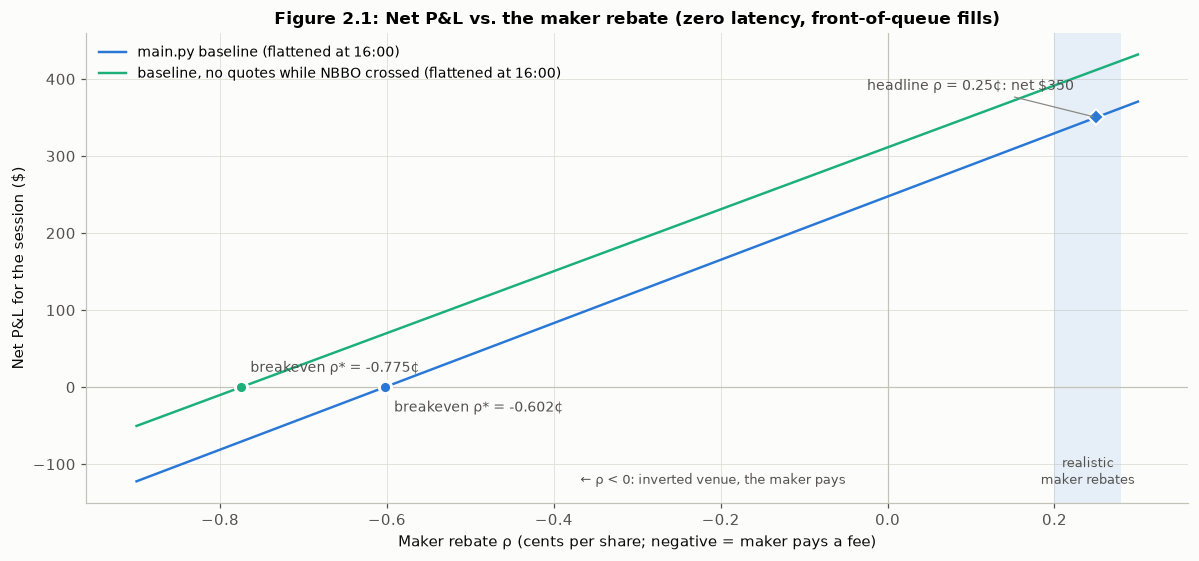

In [23]:
fig, ax = plt.subplots(figsize=(11, 5.2))
rho_c = 100 * RHO_GRID  # cents per share
ax.axvspan(100 * RHO_REALISTIC[0], 100 * RHO_REALISTIC[1], color=COLORS["real"], alpha=0.10, lw=0)
ax.axvline(0, color="#c3c2b7", lw=0.8)
ax.axhline(0, color="#c3c2b7", lw=0.8)
line_colors = {"main.py baseline": COLORS["real"], "baseline, no quotes while NBBO crossed": COLORS["accent"]}
for name, (gross, shares, flat) in variants_2.items():
    net = net_pnl(gross, shares, RHO_GRID, flat["total flattening cost ($)"])
    ax.plot(rho_c, net, color=line_colors[name], label=f"{name} (flattened at 16:00)")
    be = breakevens[name]["flattened at 16:00 with taker fee"]
    ax.plot(100 * be, 0, "o", ms=8, color=line_colors[name], mec="#fcfcfb", mew=2)
    ax.annotate(f"breakeven ρ* = {100 * be:+.3f}¢", xy=(100 * be, 0), xytext=(6, -16 if name == "main.py baseline" else 10),
                textcoords="offset points", fontsize=9, color=COLORS["ink"])
headline_net = net_pnl(gross_pnl, filled_shares, RHO_HEADLINE, flat["total flattening cost ($)"])
ax.plot(100 * RHO_HEADLINE, headline_net, "D", ms=7, color=COLORS["real"], mec="#fcfcfb", mew=1.5)
ax.annotate(f"headline ρ = {100 * RHO_HEADLINE:.2f}¢: net ${headline_net:,.0f}", xy=(100 * RHO_HEADLINE, headline_net),
            xytext=(-150, 18), textcoords="offset points", fontsize=9, color=COLORS["ink"],
            arrowprops={"arrowstyle": "-", "color": COLORS["muted"], "lw": 0.8})
ymin, ymax = ax.get_ylim()
ax.text(100 * np.mean(RHO_REALISTIC), ymin + 0.04 * (ymax - ymin), "realistic\nmaker rebates", ha="center",
        fontsize=8.5, color=COLORS["ink"])
ax.text(-0.05, ymin + 0.04 * (ymax - ymin), "← ρ < 0: inverted venue, the maker pays", fontsize=8.5,
        color=COLORS["ink"], ha="right")
ax.set_xlabel("Maker rebate ρ (cents per share; negative = maker pays a fee)")
ax.set_ylabel("Net P&L for the session ($)")
ax.set_title("Figure 2.1: Net P&L vs. the maker rebate (zero latency, front-of-queue fills)")
ax.legend(fontsize=9, loc="upper left")
fig.tight_layout()
plt.show()

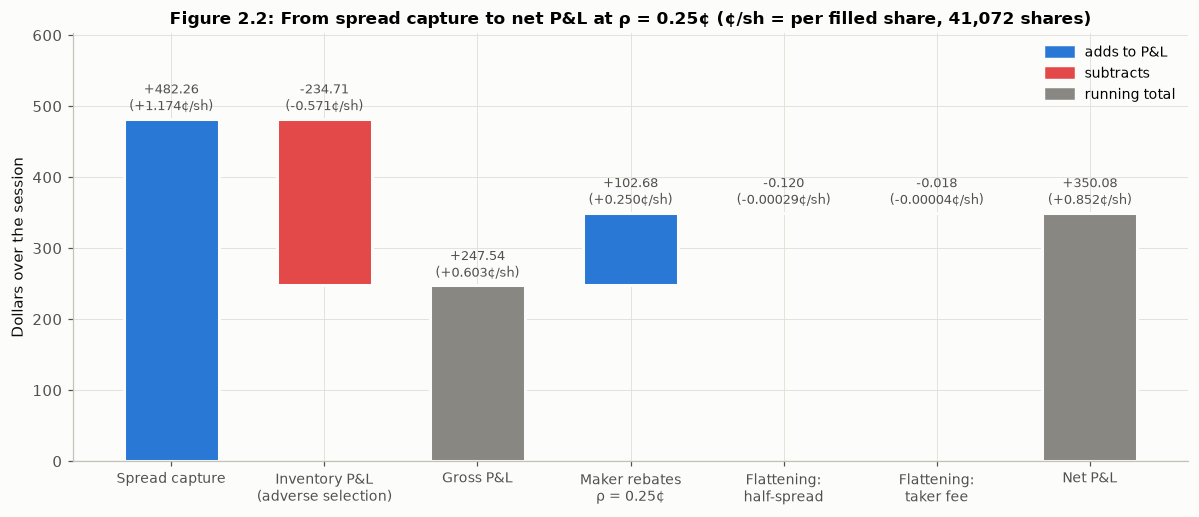

In [24]:
from matplotlib.patches import Patch

waterfall = [  # (label, change in $, or None for a running subtotal)
    ("Spread capture", real_capture),
    ("Inventory P&L\n(adverse selection)", gross_pnl - real_capture),
    ("Gross P&L", None),
    (f"Maker rebates\nρ = {100 * RHO_HEADLINE:.2f}¢", headline_rebates),
    ("Flattening:\nhalf-spread", -flat["spread cost vs mid ($)"]),
    ("Flattening:\ntaker fee", -flat["taker fee ($)"]),
    ("Net P&L", None),
]
bars, running = [], 0.0
for label, change in waterfall:
    if change is None:
        bars.append((label, 0.0, running, "total", running))
    else:
        bars.append((label, running + min(change, 0.0), abs(change), "gain" if change >= 0 else "cost", change))
        running += change
assert np.isclose(running, headline_net) and np.isclose(bars[2][4], gross_pnl)

colors = {"gain": COLORS["real"], "cost": "#e34948", "total": COLORS["muted"]}
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(bars))
ax.bar(x, [b[2] for b in bars], bottom=[b[1] for b in bars], width=0.62, color=[colors[b[3]] for b in bars],
       edgecolor="#fcfcfb", linewidth=2)
for xi, (label, bottom, height, kind, value) in zip(x, bars):
    small = abs(value) < 1  # the flattening terms: show enough digits to see them at all
    per_share = 100 * value / filled_shares
    ax.text(xi, bottom + height + 6, f"{value:+,.3f}\n({per_share:+.5f}¢/sh)" if small else
            f"{value:+,.2f}\n({per_share:+.3f}¢/sh)", ha="center", va="bottom", fontsize=8.5, color=COLORS["ink"])
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.set_xticks(x, [b[0] for b in bars], fontsize=9)
ax.set_ylim(0, max(b[1] + b[2] for b in bars) * 1.25)
ax.set_ylabel("Dollars over the session")
ax.set_title(f"Figure 2.2: From spread capture to net P&L at ρ = {100 * RHO_HEADLINE:.2f}¢ "
             f"(¢/sh = per filled share, {filled_shares:,} shares)")
ax.legend(handles=[Patch(color=colors["gain"], label="adds to P&L"), Patch(color=colors["cost"], label="subtracts"),
                   Patch(color=colors["total"], label="running total")], fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

**How much do fees and rebates matter?** Under the baseline's optimistic fill assumptions, they change *how much* the strategy makes substantially, but not *whether* it makes money.

At a realistic 0.20-0.28-cent rebate they add \$82-115 to \$247.54 of gross P&L, a third to a half more (Figure 2.1). The reason is the thin pre-fee edge: 0.603 cents per share, against a 0.25-cent rebate paid on all 41,072 filled shares. Module 8's edge equation per filled share (Figure 2.2): 1.174 cents of captured spread + 0.250 cents of rebates - 0.0003 cents of flattening spread and fee - 0.571 cents lost on inventory = **0.852 cents net**, or \$350.08 for the day. Inventory P&L stands in for the adverse-selection term until Section 6 measures it directly with markout.

Fees alone cannot make this baseline unprofitable. Net P&L reaches zero only at **$\rho^*$ = -0.602 cents**, a venue charging makers twice the taker fee, and at an inverted -0.30 cents the strategy still clears \$124. The end-of-day taker trade is a rounding error: **\$0.018 in fees, 0.02% of the rebates**.

Two caveats. First, the rebate is paid per filled share, so any overcounting of fills inflates it too. 14% of fills were marketable when placed and would actually pay the taker fee (-\$31.50 at headline rates), and 1b found that 53% of fills are triggered by off-exchange prints that a lit resting order would never receive. Second, as Sections 3-6 bring the gross edge down to a more realistic level, the fixed 0.25-cent rebate becomes a larger share of what remains.

**For the head trader:** on this tape, fees and rebates don't decide *whether* the baseline makes money, but they account for about 30% of *how much* it makes. Venue choice (standard maker-taker vs inverted) should be made together with the latency and queue-position results, not after them.

## Section 3 - Latency: How Much Does Speed Cost You?

**What stays fixed.** Same strategy (`main.handle_next_tick`), front-of-queue fill model, full-session window and Section 2 fee setup (0.25-cent maker rebate on every fill, flattening at 16:00 with the 0.30-cent taker fee). Only latency changes.

### 3a - Latency model

`LatencyBroker` extends `TapeBroker` and adds a fixed one-way latency $L$ to both legs, in tape time:
- **Outbound.** `send_limit_order` and `cancel_order` requests are queued and reach the exchange $L$ ms after the strategy sends them. Until then the exchange keeps matching against whatever was resting before.
- **Market data.** Every message from the exchange (quote updates, trade prints and our own fills) is queued and delivered to the strategy $L$ ms after it occurred. The strategy quotes off an NBBO that is $L$ ms old and learns of its fills $L$ ms late.

Together that is a $2L$ reaction time. Matching still happens at the exchange in real tape time, which creates the race the prompt describes. Suppose the market drops through our bid. We don't *see* the drop until $L$ after it happens, and our cancel and new lower quote don't land until another $L$ after that. Throughout that window the old bid rests above the new market, and any seller trading at or below it fills us. That is the stale order getting picked off, and nothing extra has to be coded for it because the two queues produce it on their own. We track it with two counters: fills that occur while a cancel for that side is already in flight, and fills on quotes that sat at or through the far side of the real NBBO when hit.

Two smaller details. Regular-session day orders expire at 16:00, so nothing fills after the close however late a cancel arrives. Order acknowledgements aren't modeled because `main.py` ignores them. With $L = 0$ the broker must behave exactly like `TapeBroker`, which we verify on the first 300,000 messages below.

In [25]:
from collections import deque
from datetime import timedelta


class LatencyBroker(TapeBroker):
    """TapeBroker with a fixed one-way latency on both legs, in tape time (see 3a)."""

    def __init__(self, data_path, latency_ms):
        super().__init__(data_path)
        self.latency = timedelta(milliseconds=latency_ms)
        self._outbound = deque()  # (time it reaches the exchange, FakeBroker method, args)
        self._inbound = deque()   # (time the strategy sees it, message)
        self._now = None          # tape time of the latest line read, i.e. the strategy's clock
        self._cancels_in_flight = {"buy": 0, "sell": 0}
        self.fills_with_cancel_in_flight = 0

    def send_limit_order(self, side, price, size):
        self._outbound.append((self._now + self.latency, FakeBroker.send_limit_order, (side, price, size)))

    def cancel_order(self, side):
        self._cancels_in_flight[side] += 1
        self._outbound.append((self._now + self.latency, FakeBroker.cancel_order, (side,)))

    def poll(self):
        event = self._read_event()
        if event is None:
            return []
        self._now = event.time
        while self._outbound and self._outbound[0][0] <= event.time:  # requests that have reached the exchange
            _, action, args = self._outbound.popleft()
            action(self, *args)
            if action is FakeBroker.cancel_order:
                self._cancels_in_flight[args[0]] -= 1
        if event.time >= SESSION_CLOSE:
            self._resting.clear()  # day orders expire at the close
        fills = self._exchange_step(event)
        self.fills_with_cancel_in_flight += sum(f.size > 0 and self._cancels_in_flight[f.side] > 0 for f in fills)
        for message in (event, *fills):
            self._inbound.append((event.time + self.latency, message))
        self._pending_broker_messages.clear()  # acks aren't modelled (main.py ignores them)
        released = []
        while self._inbound and self._inbound[0][0] <= event.time:
            released.append(self._inbound.popleft()[1])
        return released


# Check: with zero latency the broker has to match the plain TapeBroker fill for fill.
plain = run_session(max_messages=CHECK_WINDOW)
zero_latency = run_session(broker_cls=partial(LatencyBroker, latency_ms=0), max_messages=CHECK_WINDOW)
assert zero_latency.fills[fill_key].equals(plain.fills[fill_key])
assert zero_latency.book["cash"] == plain.book["cash"] and zero_latency.book["inventory"] == plain.book["inventory"]
print(f"L = 0 reproduces TapeBroker on the first {CHECK_WINDOW:,} messages ({len(plain.fills):,} identical fills)")
del plain, zero_latency

L = 0 reproduces TapeBroker on the first 300,000 messages (4,292 identical fills)


### 3b - Running the latency grid

We run the full session at $L$ = 1, 5, 20, 100 and 500 ms (the prompt's grid), plus 200 ms because a first pass placed the breakeven between 100 and 500 ms. $L = 0$ reuses the Section 1 baseline, which the check above shows the latency broker reproduces. For each run we report net P&L (gross P&L at the 16:00 mid, plus rebates, minus flattening cost), shares filled, and average **markout-free spread capture** per share: (mid at the fill - buy price) or (sell price - mid at the fill), using the real pre-trade mid at the exchange. It is "markout-free" because it looks only at the moment of the fill, not at where the price goes afterwards.

In [26]:
LATENCIES_MS = [0, 1, 5, 20, 100, 200, 500]  # the prompt's grid plus 200 ms to pin down the breakeven
latency_runs = {0: baseline}
for latency_ms in LATENCIES_MS[1:]:
    latency_runs[latency_ms] = run_session(broker_cls=partial(LatencyBroker, latency_ms=latency_ms))
    assert latency_runs[latency_ms].messages_read == baseline.messages_read  # same tape and window
    print(f"L = {latency_ms:>3} ms done in {latency_runs[latency_ms].elapsed_s:.0f} s")


def latency_metrics(result):
    f = result.fills
    p = session_paths(f, quotes)
    shares = int(f["size"].sum())
    gross = p["pnl"].iloc[-1]
    flat_cost = flatten_at_close(p)["total flattening cost ($)"]
    capture = (f["signed"] * (f["mid"] - f["price"])).sum()
    through_touch = (((f["side"] == "buy") & (f["price"] >= f["ask"] - 1e-9))
                     | ((f["side"] == "sell") & (f["price"] <= f["bid"] + 1e-9)))
    return {
        "fills (shares)": shares,
        "gross P&L ($)": gross,
        "net P&L ($)": net_pnl(gross, shares, RHO_HEADLINE, flat_cost),
        "spread capture per share (c)": 100 * capture / shares,
        "inventory P&L ($)": gross - capture,
        "fills on quotes through the touch (%)": 100 * through_touch.mean(),
        "fills with a cancel already sent (%)": 100 * getattr(result.broker, "fills_with_cancel_in_flight", 0) / shares,
        "max drawdown ($)": (np.maximum.accumulate(p["pnl"]) - p["pnl"]).max(),
        "max |inventory| (shares)": p["inventory"].abs().max(),
    }


latency_table = pd.DataFrame({L: latency_metrics(r) for L, r in latency_runs.items()}).T
latency_table.index.name = "latency L (ms)"
display(latency_table.style.format("{:,.2f}").format("{:,.0f}", subset=["fills (shares)"]))

def breakeven(series):
    """Latency where the series first turns from positive to <= 0, interpolated linearly in log(L)."""
    for lo, hi in zip(LATENCIES_MS[:-1], LATENCIES_MS[1:]):
        if series[lo] > 0 >= series[hi]:
            share = series[lo] / (series[lo] - series[hi])  # fraction of the way from lo to hi
            return lo, hi, hi * share if lo == 0 else 10 ** (np.log10(lo) + share * (np.log10(hi) - np.log10(lo)))
    return None


for label, column in (("net P&L", "net P&L ($)"), ("gross P&L (no rebates or flattening)", "gross P&L ($)")):
    crossing = breakeven(latency_table[column])
    if crossing:
        print(f"{label} turns negative between {crossing[0]} and {crossing[1]} ms; interpolated about {crossing[2]:.0f} ms")
    else:
        print(f"{label} stays positive at every latency tested")
net_crossing = breakeven(latency_table["net P&L ($)"])
breakeven_ms = net_crossing[2] if net_crossing else None

L =   1 ms done in 90 s


L =   5 ms done in 91 s


L =  20 ms done in 90 s


L = 100 ms done in 90 s


L = 200 ms done in 90 s


L = 500 ms done in 90 s


,fills (shares),gross P&L ($),net P&L ($),spread capture per share (c),inventory P&L ($),fills on quotes through the touch (%),fills with a cancel already sent (%),max drawdown ($),max |inventory| (shares)
latency L (ms),,,,,,,,,
0,"41,072",247.54,350.08,1.17,-234.71,13.95,0.00,81.65,20.00
1,"36,020",90.54,180.41,0.84,-211.20,12.26,33.39,102.48,49.00
5,"35,928",111.18,200.82,0.94,-225.34,12.13,36.19,97.01,68.00
20,"37,733",137.14,231.31,0.90,-200.66,14.58,47.30,70.69,29.00
100,"46,278",-20.15,95.36,0.35,-184.30,29.63,85.75,149.75,27.00
200,"53,753",-330.29,-196.16,-0.29,-176.75,43.65,94.58,358.31,46.00
500,"67,937","-1,454.93","-1,285.20",-1.90,-162.27,65.64,99.46,"1,458.81",109.00


net P&L turns negative between 100 and 200 ms; interpolated about 125 ms
gross P&L (no rebates or flattening) turns negative between 20 and 100 ms; interpolated about 81 ms


### 3c - Plots

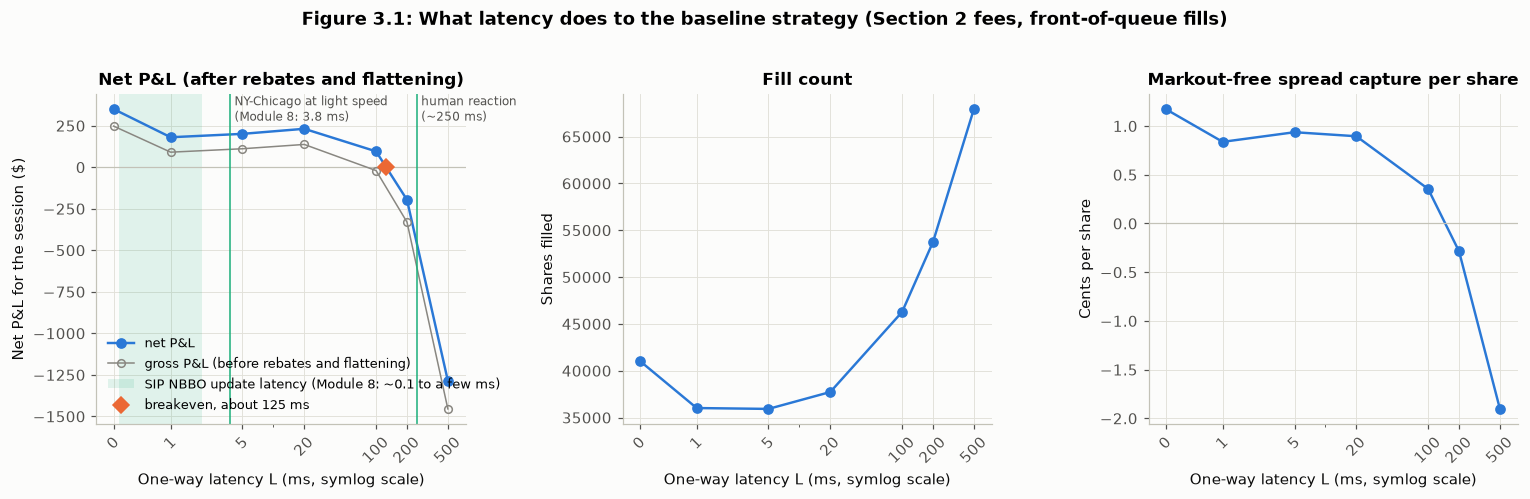

In [27]:
x = np.array(LATENCIES_MS, dtype=float)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
panels = [
    ("net P&L ($)", "Net P&L for the session ($)", "Net P&L (after rebates and flattening)"),
    ("fills (shares)", "Shares filled", "Fill count"),
    ("spread capture per share (c)", "Cents per share", "Markout-free spread capture per share"),
]
for ax, (column, ylabel, title) in zip(axes, panels):
    ax.plot(x, latency_table[column], marker="o", ms=6, color=COLORS["real"])
    if column != "fills (shares)":
        ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.set_xscale("symlog", linthresh=1, linscale=0.5)
    ax.set_xlim(-0.3, 750)
    ax.set_xticks(x, [f"{int(v)}" for v in x], rotation=45)
    ax.set_xlabel("One-way latency L (ms, symlog scale)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].plot(x, latency_table["gross P&L ($)"], marker="o", ms=5, lw=1, color=COLORS["muted"], mfc="none",
             label="gross P&L (before rebates and flattening)")
axes[0].lines[0].set_label("net P&L")
axes[0].axvspan(0.1, 2, color=COLORS["accent"], alpha=0.12, lw=0, label="SIP NBBO update latency (Module 8: ~0.1 to a few ms)")
for ref_ms, label in ((3.8, "NY-Chicago at light speed\n(Module 8: 3.8 ms)"), (250, "human reaction\n(~250 ms)")):
    axes[0].axvline(ref_ms, color=COLORS["accent"], lw=1)
    axes[0].text(ref_ms * 1.1, axes[0].get_ylim()[1], label, fontsize=8, color=COLORS["ink"], va="top")
if breakeven_ms is not None:
    axes[0].plot(breakeven_ms, 0, "D", ms=7, color=COLORS["sim"], label=f"breakeven, about {breakeven_ms:.0f} ms")
axes[0].legend(fontsize=8.5, loc="lower left")
fig.suptitle("Figure 3.1: What latency does to the baseline strategy (Section 2 fees, front-of-queue fills)",
             fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

**What latency does.** Net P&L falls from \$350.08 at $L$ = 0 to \$180.41 at 1 ms, holds between about \$180 and \$231 from 1 to 20 ms, drops to \$95.36 at 100 ms, and turns negative beyond that (-\$196.16 at 200 ms, -\$1,285.20 at 500 ms). There are three regimes.

1. *The first millisecond is the most expensive.* At $L$ = 0 the strategy re-quotes between every pair of messages, even prints microseconds apart, which no real system can do. 1b showed that trades arrive in bursts of about 2.9 prints within 1 ms, so with even 1 ms of latency the strategy cannot react inside a burst. Because `main.py` cancels and replaces on every message, it keeps re-sending quotes without knowing it has already been filled, and the same stale price can be hit more than once in a single sweep. That is also why inventory blows through the $\pm$20 limit (49 shares at 1 ms, 109 at 500 ms): `main.py`'s limit check uses the inventory the strategy *knows* about, which is $L$ ms stale. A third of fills at 1 ms (33.4%) occur while a cancel for that side is already in flight.
2. *From 1 to 20 ms, little changes.* Net P&L stays between \$180 and \$231, spread capture between 0.84 and 0.94 cents per share, and fills around 36,000-38,000 shares. 20 ms comes out slightly ahead of 1 ms, but with a single day of data that is within the noise, and we don't read anything into it.
3. *From 100 ms on, stale quotes get picked off.* The share of fills on quotes already at or through the far side of the market rises from 12-15% to 29.6% at 100 ms, 43.6% at 200 ms and 65.6% at 500 ms. Markout-free capture falls to 0.35 cents at 100 ms and turns negative after that (-0.29 cents at 200 ms, -1.90 at 500 ms), meaning that on average the strategy buys above the mid and sells below it. It also trades *more*, not less (46,278 shares at 100 ms, 67,937 at 500 ms), because a stale quote on the wrong side of the market gets hit by almost any trade. At 500 ms, 99.5% of fills land on an order we have already tried to cancel.

### 3d - Where the strategy stops being profitable

Net P&L crosses zero between 100 and 200 ms, at about 125 ms interpolating on the log scale. Without rebates the strategy stops making money sooner, at about 80 ms (gross P&L goes from \$137.14 at 20 ms to -\$20.15 at 100 ms).

One adjustment narrows that range. Some of the through-the-touch fills at high latency came from orders that were already marketable when they *reached* the exchange. Those would have executed immediately as taker orders and paid the fee rather than earning the rebate. Treating every through-the-touch fill that way gives an upper bound on the correction: at 100 ms it removes about \$75 (29.6% of 46,278 shares $\times$ 0.55 cents), leaving net P&L at roughly \$20. The breakeven therefore sits between about 100 and 125 ms.

Against Module 8's latency table: the SIP's consolidated NBBO updates in hundreds of microseconds to a few milliseconds, and even a signal travelling from New York to Chicago at the speed of light takes 3.8 ms. A colocated firm on direct feeds is faster than all of these. Every one is far below 100 ms, so any automated setup, even one reading the slower SIP, keeps this strategy profitable in the backtest. A person watching a screen does not. Noticing a quote change and reacting takes roughly a quarter of a second (a standard human reaction-time figure, not from the slides), which is past the breakeven, and at 200-500 ms the strategy loses \$196 to \$1,285 for the day. The breakeven sits much closer to "a human noticing a quote change" than to "colocated direct feed". The strategy must be automated, but it doesn't need to be the fastest in the market.

The bigger message is the first millisecond. Moving from 0 to 1 ms costs about \$170 of the \$350, roughly half of net P&L, because the zero-latency backtest lets the strategy react inside bursts that last less than a millisecond. No one can actually do that, so the \$350 from Section 2 overstates the opportunity, and \$180-230 is a more defensible figure for an automated setup. All of this still assumes front-of-queue fills, which Section 4 tests next.